# Marvel CPG Deep EDA and Product Insights

## Purpose

This notebook rebuilds the exploratory analysis around the decisions the product must make. It does not only profile columns. It tests whether the supplied data can support:

1. Commercial execution KPIs.
2. Seven-day out-of-stock risk and visit prioritization.
3. Margin-aware negotiation guardrails.
4. Data-aware answers in the commercial copilot.

The analysis gives special attention to missing Sell-out store-days, because missing reports affect current inventory, KPI denominators, OOS labels, and the reliability of every downstream module.

## Business interpretation used in this notebook

- An absent Sell-out store-day means **not reported**, not zero sales, zero inventory, or confirmed non-OOS.
- Sell-out inventory is end-of-day inventory after that day's sales.
- Sell-in dates are Monday invoice dates and week starts. They are not confirmed delivery dates.
- Distributor accounts are wholesale accounts and are analyzed separately from retail stores.
- The OOS target is any observed OOS event during `t+1` through `t+7`.
- June 30, 2026 is the product simulation date.

All findings are descriptive unless a section explicitly defines a predictive experiment. Audit associations are not treated as causal uplift estimates.

## Executive findings

1. **The 30% missingness is an entire-store-day reporting gap.** Exactly 154 of 221 accounts report every day. Coverage is nearly identical across months, weekdays, channels, tiers, prior OOS status, previous-sales levels, and audit days. The pattern is consistent with a synthetic fixed-size random sample rather than closures or business-driven nonreporting.
2. **Missing blocks must be validated at store-day level.** When an account reports, it reports every SKU in its observed active assortment. Randomly masking cells or SKU rows would not reproduce the production problem.
3. **The explainable sales baseline is useful but not sufficient.** A past-only store-SKU-weekday median achieves about 37.5% WAPE in June. Traditional Trade is the hardest segment at about 46% WAPE.
4. **Inventory requires a state and replenishment model.** Short-gap depletion works for one day but becomes strongly downward biased over longer gaps. A simple hybrid baseline achieves about 14.7% WAPE, but longer gaps should remain unknown unless a replenishment-aware challenger validates well.
5. **Formal OOS labels are scarce.** About 8.5% of candidate rows have complete future seven-day windows. Another 11.6% are partial-window confirmed positives; about 80% remain unknown.
6. **Days of supply is a strong and explainable risk signal.** Complete-window rows with one day or less of supply have a future OOS rate above 60%, compared with below 1% above fourteen days.
7. **Shelf execution is strongly tiered.** Tier 3 has lower MSL compliance, planogram compliance, shelf share, and secondary-display rates, and higher OOS rates. This supports a tier-aware field workflow.
8. **Negotiation controls address an observable issue.** About 12% of invoices exceed the supplied max-discount threshold, concentrated in Traditional Trade, while none breach the supplied margin floor. Approval and commitment data are missing, so these are review cases rather than proven violations.
9. **Distributor accounts need a separate wholesale workflow.** Their data uses retail concepts, but the client defines them as wholesale accounts. Retail KPIs and shelf commitments should not be applied without redesign.

## 1. Setup and data loading

The notebook locates the repository root from the current working directory, so it can run from either the repository root or the `notebooks/exploratory` folder.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = Path.cwd()
if not (ROOT / "marvel_data").exists():
    ROOT = ROOT.parents[1]
DATA = ROOT / "marvel_data"

COLORS = {
    "red": "#B7352A",
    "navy": "#26394E",
    "blue": "#58758E",
    "green": "#2F715B",
    "gray": "#8A8F94",
    "light": "#E8E5DF",
}
sns.set_theme(style="whitegrid", context="notebook")

stores = pd.read_csv(DATA / "dim_stores.csv")
products = pd.read_csv(DATA / "dim_products.csv")
guardrails = pd.read_csv(DATA / "dim_guardrails.csv")
sell_in = pd.read_csv(DATA / "fact_sell_in.csv", parse_dates=["date"])
sell_out = pd.read_csv(DATA / "fact_sell_out.csv", parse_dates=["date"])
audits = pd.read_csv(DATA / "fact_execution_audits.csv", parse_dates=["date"])

tables = {
    "dim_stores": stores,
    "dim_products": products,
    "dim_guardrails": guardrails,
    "fact_sell_in": sell_in,
    "fact_sell_out": sell_out,
    "fact_execution_audits": audits,
}

/Users/william/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/_x/4ry9nxls3g9f1840pcdmdk_m0000gn/T/matplotlib-a7p3gmga because there was an issue with the default path (/Users/william/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig

Matplotlib is building the font cache; this may take a moment.


## 2. Data contract and integrity checks

In [2]:
candidate_keys = {
    "dim_stores": ["store_id"],
    "dim_products": ["sku_id"],
    "dim_guardrails": ["channel", "category"],
    "fact_sell_in": ["transaction_id"],
    "fact_sell_out": ["date", "store_id", "sku_id"],
    "fact_execution_audits": ["audit_id"],
}

profile_rows = []
for name, df in tables.items():
    profile_rows.append({
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "null_cells": int(df.isna().sum().sum()),
        "duplicate_candidate_keys": int(df.duplicated(candidate_keys[name]).sum()),
        "date_min": df.date.min().date() if "date" in df else None,
        "date_max": df.date.max().date() if "date" in df else None,
    })

profile = pd.DataFrame(profile_rows)
display(profile)

fk_checks = pd.Series({
    "Sell-in stores not in dim_stores": (~sell_in.store_id.isin(stores.store_id)).sum(),
    "Sell-in SKUs not in dim_products": (~sell_in.sku_id.isin(products.sku_id)).sum(),
    "Sell-out stores not in dim_stores": (~sell_out.store_id.isin(stores.store_id)).sum(),
    "Sell-out SKUs not in dim_products": (~sell_out.sku_id.isin(products.sku_id)).sum(),
    "Audit stores not in dim_stores": (~audits.store_id.isin(stores.store_id)).sum(),
    "Audit SKUs not in dim_products": (~audits.sku_id.isin(products.sku_id)).sum(),
}, name="failed_rows")
display(fk_checks.to_frame())

,table,rows,columns,null_cells,duplicate_candidate_keys,date_min,date_max
0,dim_stores,221,7,0,0,None,None
1,dim_products,23,7,0,0,None,None
2,dim_guardrails,9,5,0,0,None,None
3,fact_sell_in,277969,6,0,0,2024-12-30,2026-06-29
4,fact_sell_out,1656756,6,0,0,2025-01-01,2026-06-30
5,fact_execution_audits,207020,7,0,0,2025-01-01,2026-06-30


,failed_rows
Sell-in stores not in dim_stores,0
Sell-in SKUs not in dim_products,0
Sell-out stores not in dim_stores,0
Sell-out SKUs not in dim_products,0
Audit stores not in dim_stores,0
Audit SKUs not in dim_products,0


### Integrity finding

The six tables have no null cells, duplicate candidate keys, or broken dimension references. The important missingness is structural: complete Sell-out store-days are absent from the fact table. This means a normal `isna()` report would miss the most consequential data-quality problem.

## 3. Business structure: accounts, products, and provisional economics

In [3]:
store_mix = stores.pivot_table(
    index="channel", columns="segment_tier", values="store_id", aggfunc="count", fill_value=0
)
display(store_mix.assign(Total=store_mix.sum(axis=1)))

product_mix = products.groupby(["category", "is_msl"], observed=True).size().unstack(fill_value=0)
display(product_mix)

product_economics = products.assign(
    list_price_margin_pct=100 * (products.list_price - products.unit_cost) / products.list_price
)[["sku_id", "product_name", "category", "is_msl", "unit_cost", "list_price", "list_price_margin_pct"]]
display(product_economics.sort_values("list_price_margin_pct").head(10))

print(f"Accounts: {len(stores):,} ({(stores.channel == 'Distributor').sum():,} Distributors)")
print(f"Products: {len(products):,}; global MSL products: {products.is_msl.sum():,}")
print(f"List-price gross-margin proxy range: {product_economics.list_price_margin_pct.min():.1f}% to {product_economics.list_price_margin_pct.max():.1f}%")

segment_tier,Tier 1,Tier 2,Tier 3,Total
channel,,,,
Distributor,15,10,11,36
Modern Trade,41,35,24,100
Traditional Trade,16,39,30,85


is_msl,False,True
category,,
Dishwashing,3,4
Laundry,2,6
Surface Cleaners,3,5


,sku_id,product_name,category,is_msl,unit_cost,list_price,list_price_margin_pct
15,SKU-1016,Marvel Laundry Detergent HE 100oz,Laundry,True,4.500,9.200,51.087
17,SKU-1018,Marvel Laundry Pods 42ct,Laundry,True,5.100,10.500,51.429
3,SKU-1004,Marvel Heavy-Duty Degreaser 1L,Surface Cleaners,True,2.800,5.800,51.724
18,SKU-1019,Marvel Laundry Pods 20ct,Laundry,False,2.600,5.400,51.852
7,SKU-1008,Marvel Multi-Surface Wipes 75ct,Surface Cleaners,True,2.450,5.100,51.961
21,SKU-1022,Marvel Stain Remover Spray 22oz,Laundry,True,2.200,4.600,52.174
22,SKU-1023,Marvel Bleach Clean White 96oz,Laundry,True,2.000,4.200,52.381
19,SKU-1020,Marvel Fabric Softener Lavender 64oz,Laundry,True,2.800,5.900,52.542
2,SKU-1003,Marvel Power Clean Lavender 750ml,Surface Cleaners,False,1.850,3.900,52.564
20,SKU-1021,Marvel Fabric Softener Fresh 64oz,Laundry,False,2.750,5.800,52.586


Accounts: 221 (36 Distributors)
Products: 23; global MSL products: 15
List-price gross-margin proxy range: 51.1% to 54.3%


### Product implication

The dataset contains 36 Distributor accounts alongside 185 retail stores. A single KPI and negotiation workflow would mix wholesale flow with retail shelf execution. Distributor treatment therefore needs a separate analytical view and a separate negotiation rule set.

## 4. Missing store-days: reconstructing the complete reporting calendar

,value
Possible store-days,"120,666.000"
Observed store-days,"84,084.000"
Coverage,0.697
Reporting stores per day (min),154.000
Reporting stores per day (median),154.000
Reporting stores per day (max),154.000
Store coverage minimum,0.647
Store coverage maximum,0.747


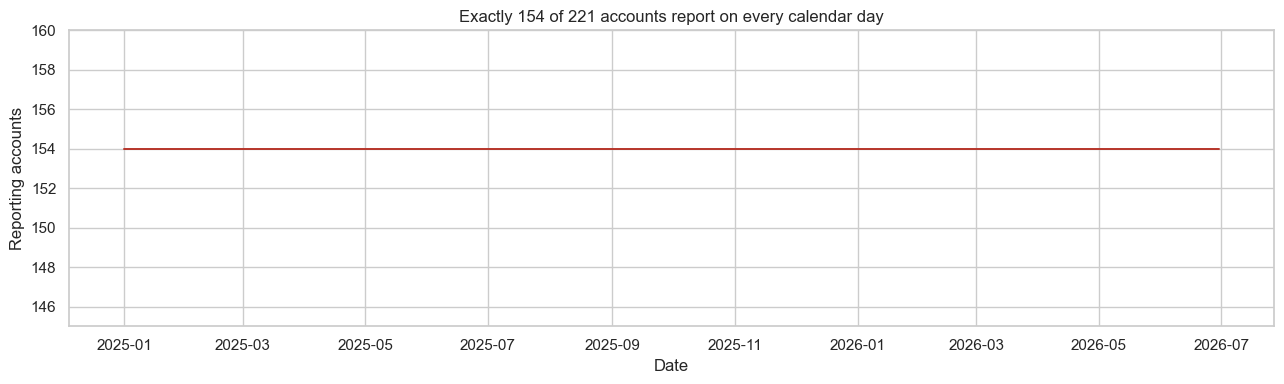

In [4]:
start_date, end_date = sell_out.date.min(), sell_out.date.max()
calendar_dates = pd.date_range(start_date, end_date, freq="D")

store_days = pd.MultiIndex.from_product(
    [calendar_dates, stores.store_id], names=["date", "store_id"]
).to_frame(index=False)
reported_store_days = sell_out[["date", "store_id"]].drop_duplicates().assign(is_reported=True)
store_days = store_days.merge(reported_store_days, on=["date", "store_id"], how="left")
store_days["is_reported"] = store_days.is_reported.fillna(False).astype(bool)
store_days = store_days.merge(
    stores[["store_id", "channel", "region", "state", "segment_tier"]],
    on="store_id", how="left", validate="many_to_one"
)
store_days["weekday"] = store_days.date.dt.day_name()
store_days["month"] = store_days.date.dt.to_period("M").astype(str)

daily_reporting = store_days.groupby("date").is_reported.agg(reporting_stores="sum", coverage="mean").reset_index()
store_coverage = store_days.groupby("store_id").is_reported.mean()

headline = pd.Series({
    "Possible store-days": len(store_days),
    "Observed store-days": int(store_days.is_reported.sum()),
    "Coverage": store_days.is_reported.mean(),
    "Reporting stores per day (min)": int(daily_reporting.reporting_stores.min()),
    "Reporting stores per day (median)": int(daily_reporting.reporting_stores.median()),
    "Reporting stores per day (max)": int(daily_reporting.reporting_stores.max()),
    "Store coverage minimum": store_coverage.min(),
    "Store coverage maximum": store_coverage.max(),
})
display(headline.to_frame("value"))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily_reporting.date, daily_reporting.reporting_stores, color=COLORS["red"], linewidth=1.4)
ax.set(title="Exactly 154 of 221 accounts report on every calendar day", xlabel="Date", ylabel="Reporting accounts")
ax.set_ylim(145, 160)
plt.tight_layout()
plt.show()

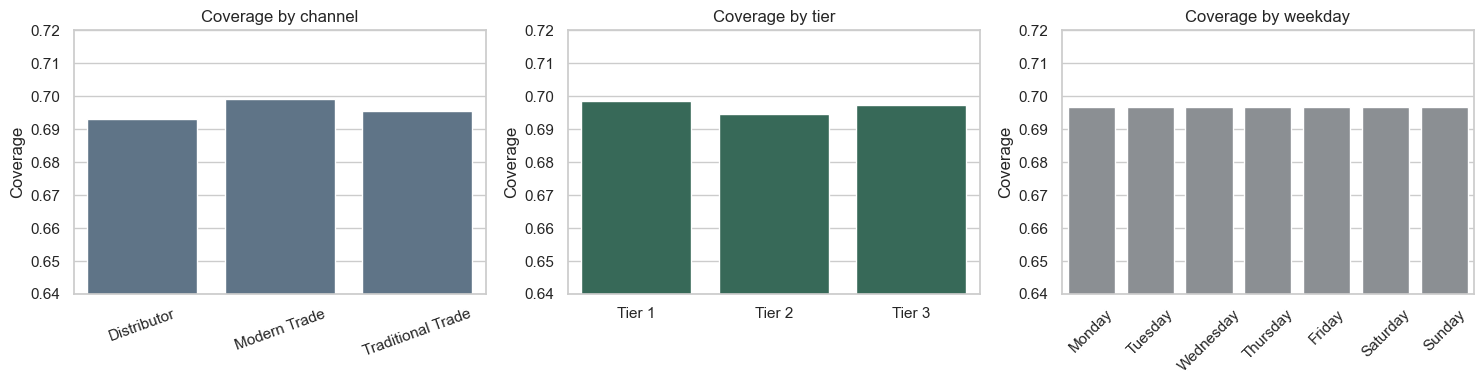

,coverage
Distributor,0.693
Modern Trade,0.699
Traditional Trade,0.695
Tier 1,0.699
Tier 2,0.695
Tier 3,0.697
Monday,0.697
Tuesday,0.697
Wednesday,0.697
Thursday,0.697


In [5]:
coverage_channel = store_days.groupby("channel", observed=True).is_reported.mean().rename("coverage")
coverage_tier = store_days.groupby("segment_tier", observed=True).is_reported.mean().rename("coverage")
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
coverage_weekday = store_days.groupby("weekday", observed=True).is_reported.mean().reindex(weekday_order).rename("coverage")
coverage_month = store_days.groupby("month", observed=True).is_reported.mean().rename("coverage")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(x=coverage_channel.index, y=coverage_channel.values, ax=axes[0], color=COLORS["blue"])
axes[0].set(title="Coverage by channel", xlabel="", ylabel="Coverage", ylim=(0.64, 0.72))
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(x=coverage_tier.index, y=coverage_tier.values, ax=axes[1], color=COLORS["green"])
axes[1].set(title="Coverage by tier", xlabel="", ylabel="Coverage", ylim=(0.64, 0.72))
sns.barplot(x=coverage_weekday.index, y=coverage_weekday.values, ax=axes[2], color=COLORS["gray"])
axes[2].set(title="Coverage by weekday", xlabel="", ylabel="Coverage", ylim=(0.64, 0.72))
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

display(pd.concat([coverage_channel, coverage_tier, coverage_weekday, coverage_month]).to_frame())

### Missingness finding 1: the reporting mechanism looks synthetic and approximately random

- Every day has exactly 154 reporting accounts, which produces 69.68% coverage.
- Monthly and weekday coverage are mathematically identical.
- Channel and tier differences are below one percentage point.
- Individual-account coverage varies within a narrow range of roughly 65% to 75%.

This is stronger evidence for a fixed-size random reporting sample than for store closures, weekday schedules, or a channel-specific reporting process. We should still preserve `Observed`, `Estimated`, and `Unknown` states because random missingness does not make the missing values known.

### 4.1 Missing-run length and reporting rotation

,days
Median missing run,1.000
95th percentile missing run,3.000
Maximum missing run,10.000


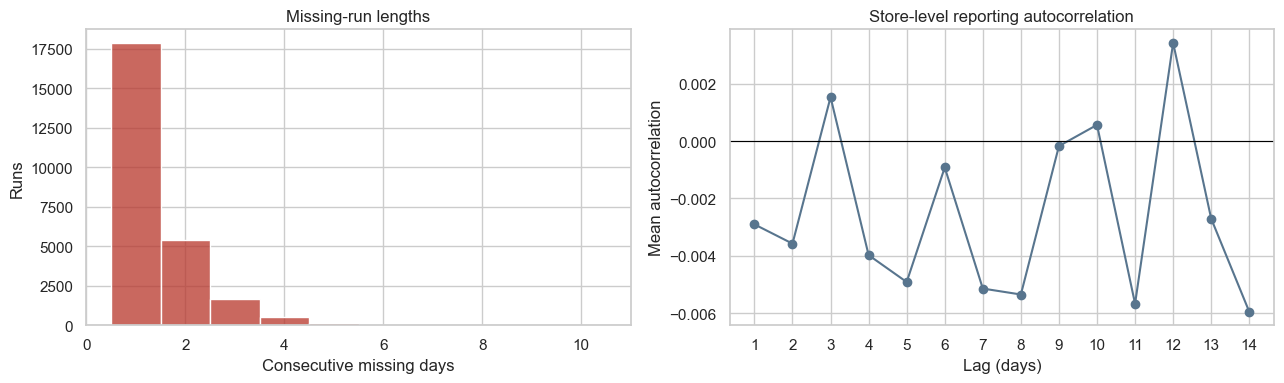

In [6]:
def run_lengths(mask):
    padded = np.r_[False, mask, False].astype(np.int8)
    changes = np.diff(padded)
    return np.flatnonzero(changes == -1) - np.flatnonzero(changes == 1)

missing_runs = []
for store_id, group in store_days.sort_values("date").groupby("store_id", sort=False):
    missing_runs.extend(run_lengths((~group.is_reported).to_numpy()))
missing_runs = pd.Series(missing_runs, name="missing_run_length")

report_matrix = store_days.pivot(index="date", columns="store_id", values="is_reported").astype(float)
autocorr = pd.Series({lag: np.nanmean([report_matrix[c].autocorr(lag=lag) for c in report_matrix]) for lag in range(1, 15)})

display(pd.Series({
    "Median missing run": missing_runs.median(),
    "95th percentile missing run": missing_runs.quantile(0.95),
    "Maximum missing run": missing_runs.max(),
}).to_frame("days"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(missing_runs.clip(upper=10), discrete=True, ax=axes[0], color=COLORS["red"])
axes[0].set(title="Missing-run lengths", xlabel="Consecutive missing days", ylabel="Runs")
axes[1].plot(autocorr.index, autocorr.values, marker="o", color=COLORS["blue"])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Store-level reporting autocorrelation", xlabel="Lag (days)", ylabel="Mean autocorrelation", xticks=range(1, 15))
plt.tight_layout()
plt.show()

### Missingness finding 2: gaps are short and there is no stable rotation

The median gap is one day, 95% of gaps are three days or shorter, and the maximum is ten days. Reporting autocorrelation is close to zero at lags 1–14, including the seven-day lag. This does not support a fixed weekly rotation by store.

### 4.2 Does missingness follow OOS, high sales, or audits?

In [7]:
store_day_state = sell_out.groupby(["date", "store_id"], observed=True).agg(
    total_units=("units_sold_daily", "sum"),
    any_oos=("is_out_of_stock", "max"),
    reported_skus=("sku_id", "nunique"),
    total_inventory=("inventory_level", "sum"),
).reset_index()

state_calendar = store_days[["date", "store_id", "is_reported"]].merge(
    store_day_state, on=["date", "store_id"], how="left"
).sort_values(["store_id", "date"])
state_calendar["prev_any_oos"] = state_calendar.groupby("store_id").any_oos.shift(1)
state_calendar["prev_total_units"] = state_calendar.groupby("store_id").total_units.shift(1)

prev_known = state_calendar.prev_any_oos.notna()
p_missing_oos = 1 - state_calendar.loc[prev_known & state_calendar.prev_any_oos.eq(True), "is_reported"].mean()
p_missing_no_oos = 1 - state_calendar.loc[prev_known & state_calendar.prev_any_oos.eq(False), "is_reported"].mean()

known_sales = state_calendar.loc[state_calendar.prev_total_units.notna()].copy()
known_sales["previous_sales_quartile"] = pd.qcut(known_sales.prev_total_units, 4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop")
p_missing_sales = 1 - known_sales.groupby("previous_sales_quartile", observed=True).is_reported.mean()

audit_days = audits[["date", "store_id"]].drop_duplicates().assign(has_audit=True)
audit_compare = state_calendar.merge(audit_days, on=["date", "store_id"], how="left")
audit_compare["has_audit"] = audit_compare.has_audit.fillna(False).astype(bool)

conditional = pd.Series({
    "Missing after prior observed OOS store-day": p_missing_oos,
    "Missing after prior observed non-OOS store-day": p_missing_no_oos,
    "Coverage on audit store-days": audit_compare.loc[audit_compare.has_audit, "is_reported"].mean(),
    "Coverage on non-audit store-days": audit_compare.loc[~audit_compare.has_audit, "is_reported"].mean(),
})
display(conditional.to_frame("rate"))
display(p_missing_sales.to_frame("next-day missing rate"))

,rate
Missing after prior observed OOS store-day,0.304
Missing after prior observed non-OOS store-day,0.303
Coverage on audit store-days,0.700
Coverage on non-audit store-days,0.697


,next-day missing rate
previous_sales_quartile,
Q1,0.300
Q2,0.306
Q3,0.308
Q4,0.301


### Missingness finding 3: the probability of missingness is practically unchanged

The next-day missing rate is about 30.3% after both OOS and non-OOS store-days. It is also stable across previous-sales quartiles. Audit-day coverage is almost the same as non-audit-day coverage. For this synthetic dataset, missingness is therefore close to **MCAR at the store-day level**.

This conclusion applies to the *reporting indicator*. It does not mean that sales and inventory values should be filled with overall averages. Value estimation still needs store, SKU, tier, weekday, inventory state, and replenishment context.

### 4.3 Missingness occurs at the complete store-day level

In [8]:
active_pairs = sell_out[["store_id", "sku_id"]].drop_duplicates()
active_skus = active_pairs.groupby("store_id").size().rename("ever_active_skus")
store_day_completeness = store_day_state.merge(active_skus, on="store_id", how="left")
store_day_completeness["sku_coverage"] = store_day_completeness.reported_skus / store_day_completeness.ever_active_skus

display(pd.Series({
    "Active store-SKU pairs": len(active_pairs),
    "Minimum active SKUs per account": active_skus.min(),
    "Median active SKUs per account": active_skus.median(),
    "Maximum active SKUs per account": active_skus.max(),
    "Observed store-days with full active assortment": store_day_completeness.sku_coverage.eq(1).mean(),
}).to_frame("value"))

,value
Active store-SKU pairs,"4,355.000"
Minimum active SKUs per account,15.000
Median active SKUs per account,20.000
Maximum active SKUs per account,23.000
Observed store-days with full active assortment,1.000


### Missingness finding 4: mask entire store-days in validation

Whenever an account reports, all SKUs in its observed active assortment are present. The experimental unit for missing-data validation must therefore be a **store-day block**, not independent random cells or SKU rows. Cell-level random masking would make the task artificially easy and would not reproduce the production problem.

## 5. Missing-value experiments

### 5.1 Sales estimation benchmark

The first benchmark learns only from in-stock observations through May 31, 2026 and predicts observed in-stock rows in June. This preserves time order and avoids learning normal demand from censored OOS days.

Methods:

1. Zero fill as a control.
2. Store-SKU median.
3. Store-SKU-weekday median with store-SKU fallback.
4. Hierarchical median with channel, tier, SKU, category, and weekday fallbacks.

This is a baseline experiment, not the final masked-block validation.

,MAE,WAPE,Bias
zero,4.574,1.000,-4.574
store_sku_median,1.736,0.380,0.198
store_sku_weekday_median,1.717,0.375,0.200
hierarchical_median,1.717,0.375,0.200


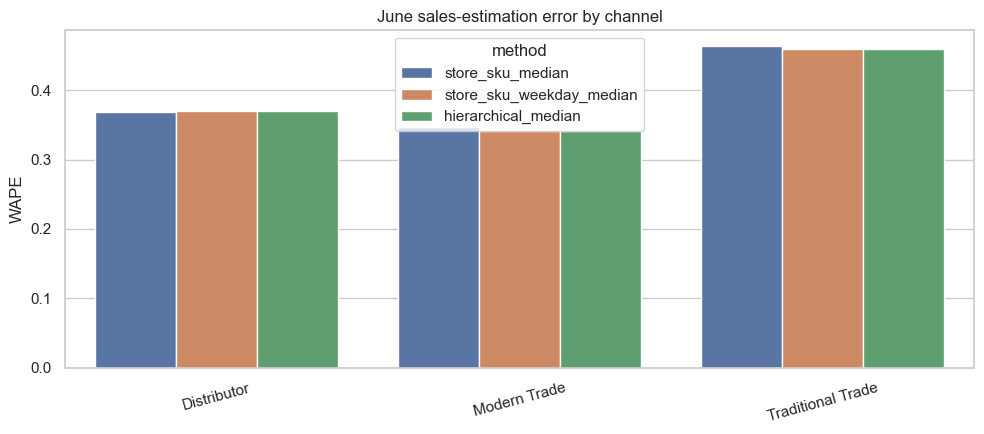

In [9]:
so = sell_out.merge(
    stores[["store_id", "channel", "segment_tier", "region"]], on="store_id", how="left", validate="many_to_one"
).merge(
    products[["sku_id", "product_name", "category", "is_msl", "unit_cost", "list_price"]],
    on="sku_id", how="left", validate="many_to_one"
)

cutoff = pd.Timestamp("2026-05-31")
train = so.loc[(so.date <= cutoff) & ~so.is_out_of_stock].copy()
test = so.loc[(so.date > cutoff) & ~so.is_out_of_stock].copy()
train["weekday"] = train.date.dt.dayofweek
test["weekday"] = test.date.dt.dayofweek

median_store_sku_weekday = train.groupby(["store_id", "sku_id", "weekday"], observed=True).units_sold_daily.median()
median_store_sku = train.groupby(["store_id", "sku_id"], observed=True).units_sold_daily.median()
median_tier_sku_weekday = train.groupby(["channel", "segment_tier", "sku_id", "weekday"], observed=True).units_sold_daily.median()
median_channel_sku_weekday = train.groupby(["channel", "sku_id", "weekday"], observed=True).units_sold_daily.median()
median_category_tier_weekday = train.groupby(["category", "segment_tier", "weekday"], observed=True).units_sold_daily.median()

def map_multi(series, frame, cols):
    return series.reindex(pd.MultiIndex.from_frame(frame[cols])).to_numpy(dtype=float)

p1 = map_multi(median_store_sku_weekday, test, ["store_id", "sku_id", "weekday"])
p2 = map_multi(median_store_sku, test, ["store_id", "sku_id"])
p3 = map_multi(median_tier_sku_weekday, test, ["channel", "segment_tier", "sku_id", "weekday"])
p4 = map_multi(median_channel_sku_weekday, test, ["channel", "sku_id", "weekday"])
p5 = map_multi(median_category_tier_weekday, test, ["category", "segment_tier", "weekday"])

test["zero"] = 0.0
test["store_sku_median"] = p2
test["store_sku_weekday_median"] = np.where(np.isfinite(p1), p1, p2)
test["hierarchical_median"] = np.where(
    np.isfinite(p1), p1,
    np.where(np.isfinite(p2), p2, np.where(np.isfinite(p3), p3, np.where(np.isfinite(p4), p4, p5)))
)

def score(actual, prediction):
    return pd.Series({
        "MAE": (actual - prediction).abs().mean(),
        "WAPE": (actual - prediction).abs().sum() / actual.abs().sum(),
        "Bias": (prediction - actual).mean(),
    })

sales_scores = pd.concat({m: score(test.units_sold_daily, test[m]) for m in [
    "zero", "store_sku_median", "store_sku_weekday_median", "hierarchical_median"
]}, axis=1).T
display(sales_scores)

channel_scores = []
for channel, group in test.groupby("channel", observed=True):
    for method in ["store_sku_median", "store_sku_weekday_median", "hierarchical_median"]:
        s = score(group.units_sold_daily, group[method])
        channel_scores.append({"channel": channel, "method": method, **s.to_dict()})
channel_scores = pd.DataFrame(channel_scores)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=channel_scores, x="channel", y="WAPE", hue="method", ax=ax)
ax.set(title="June sales-estimation error by channel", xlabel="", ylabel="WAPE")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### Sales benchmark interpretation

- Replacing missing sales with zero produces 100% WAPE and is not defensible.
- Store-SKU medians reduce WAPE to about 38% overall.
- Weekday conditioning provides a small improvement, mainly in Modern Trade.
- Traditional Trade remains the hardest channel, with roughly 46% WAPE.

The baseline is useful for an explainable MVP but not accurate enough to be presented as actual sales. Estimated sales must remain labeled, and model-based challengers should be tested against the same time-based masked-store-day evaluation.

### 5.2 Inventory state benchmark on real reporting gaps

,method,gap_days,rows,MAE,WAPE,Bias,OOS accuracy
0,ffill,All,90925,8.120,0.188,0.210,0.965
8,depletion,All,90925,7.094,0.164,-6.097,0.952
16,hybrid,All,90925,6.374,0.147,-2.904,0.965


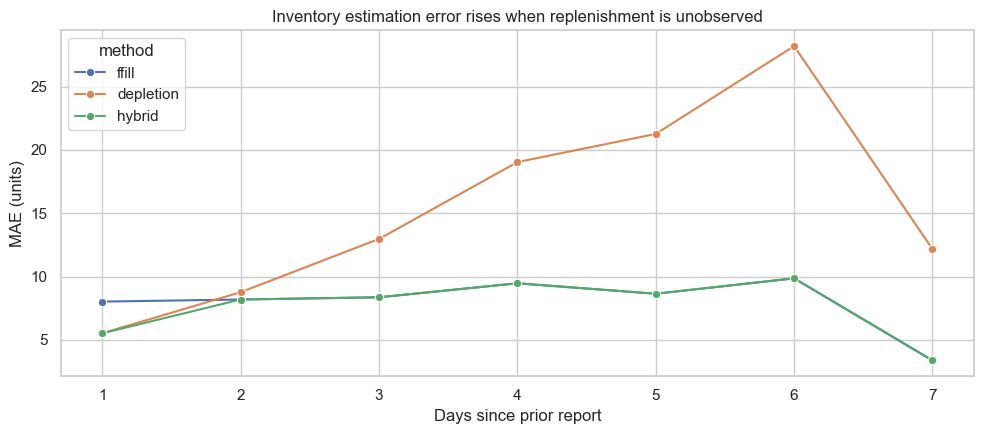

In [10]:
inv = sell_out.sort_values(["store_id", "sku_id", "date"]).copy()
inv["prev_date"] = inv.groupby(["store_id", "sku_id"]).date.shift(1)
inv["prev_inventory"] = inv.groupby(["store_id", "sku_id"]).inventory_level.shift(1)
inv["gap_days"] = (inv.date - inv.prev_date).dt.days
inv = inv.loc[(inv.date > cutoff) & inv.prev_inventory.notna() & inv.gap_days.between(1, 7)].copy()

idx = pd.MultiIndex.from_frame(inv[["store_id", "sku_id"]])
inv["sales_rate"] = median_store_sku.reindex(idx).to_numpy(dtype=float)
inv["ffill"] = inv.prev_inventory
inv["depletion"] = (inv.prev_inventory - inv.sales_rate.fillna(0) * inv.gap_days).clip(lower=0)
inv["hybrid"] = np.where(inv.gap_days.eq(1), inv.depletion, inv["ffill"])

inventory_rows = []
for method in ["ffill", "depletion", "hybrid"]:
    for gap, group in [("All", inv), *[(str(int(k)), v) for k, v in inv.groupby("gap_days")]]:
        inventory_rows.append({
            "method": method,
            "gap_days": gap,
            "rows": len(group),
            "MAE": (group.inventory_level - group[method]).abs().mean(),
            "WAPE": (group.inventory_level - group[method]).abs().sum() / group.inventory_level.abs().sum(),
            "Bias": (group[method] - group.inventory_level).mean(),
            "OOS accuracy": (group[method].eq(0) == group.inventory_level.eq(0)).mean(),
        })
inventory_scores = pd.DataFrame(inventory_rows)
display(inventory_scores.query("gap_days == 'All'"))

gap_plot = inventory_scores.query("gap_days != 'All'").copy()
gap_plot["gap_days"] = gap_plot.gap_days.astype(int)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=gap_plot, x="gap_days", y="MAE", hue="method", marker="o", ax=ax)
ax.set(title="Inventory estimation error rises when replenishment is unobserved", xlabel="Days since prior report", ylabel="MAE (units)")
plt.tight_layout()
plt.show()

### Inventory benchmark interpretation

- Depleting the previous inventory by expected sales works best for a one-day interval.
- For gaps of two or more days, it increasingly underestimates inventory because it cannot observe replenishment.
- A simple hybrid rule—deplete for a one-day gap and otherwise retain the last state—improves overall WAPE to about 15%, but it remains a baseline.

The next experiment should mask complete observed store-day blocks using the real gap-length distribution. Candidate inventory methods should include forward fill, short-gap depletion, a state-space model, and a replenishment-aware model using lagged Sell-in signals. Performance must be reported by gap length, channel, tier, and OOS status.

### 5.3 Recommended missing-data experiment design

1. **Split by time first.** Fit methods through May 2026 and evaluate on June 2026.
2. **Mask complete store-days.** Sample block lengths from the observed missing-run distribution. Never mask isolated cells.
3. **Preserve two targets.** Evaluate sales and inventory separately.
4. **Sales metrics.** MAE, WAPE, bias, and error by channel, tier, SKU, weekday, and gap length.
5. **Inventory metrics.** MAE, WAPE, bias, zero-inventory classification, and inventory-bucket accuracy.
6. **OOS impact.** Recompute operational KPIs and OOS-risk features after imputation and measure the change.
7. **No imputed labels.** Future imputed inventory must not become formal OOS ground truth.
8. **Selection rule.** Prefer the simplest method that is materially competitive and stable across segments. Use `Unknown` when the gap exceeds the validated operating range.

## 6. OOS patterns and visit-prioritization signals

,value
OOS rows,"98,953.000"
Overall observed OOS rate,0.060
OOS flag / zero inventory mismatches,0.000
OOS rows with positive same-day sales,"29,892.000"
Share of OOS rows with positive same-day sales,0.302


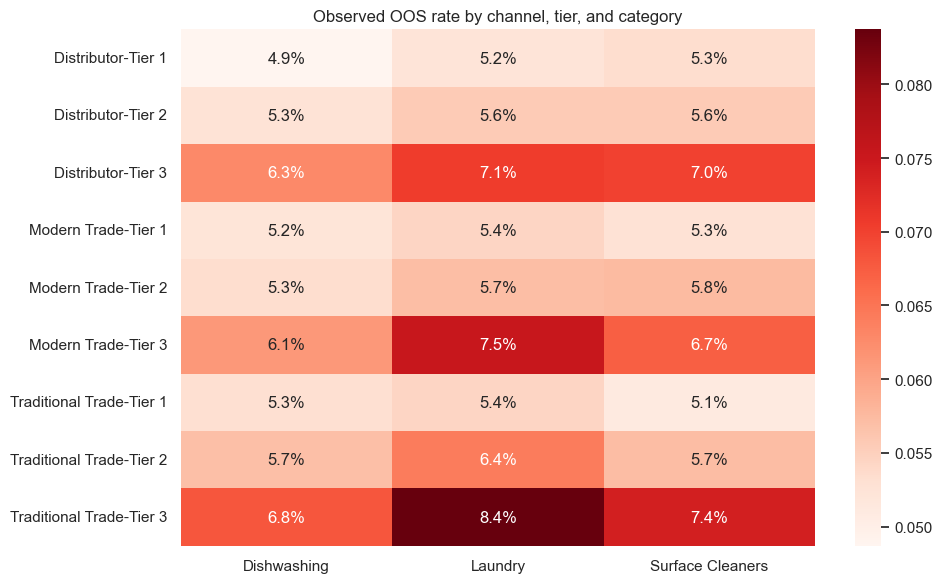

In [11]:
integrity = pd.Series({
    "OOS rows": int(so.is_out_of_stock.sum()),
    "Overall observed OOS rate": so.is_out_of_stock.mean(),
    "OOS flag / zero inventory mismatches": int((so.is_out_of_stock != so.inventory_level.eq(0)).sum()),
    "OOS rows with positive same-day sales": int((so.is_out_of_stock & so.units_sold_daily.gt(0)).sum()),
    "Share of OOS rows with positive same-day sales": (
        so.is_out_of_stock & so.units_sold_daily.gt(0)
    ).sum() / so.is_out_of_stock.sum(),
})
display(integrity.to_frame("value"))

oos_segment = so.groupby(["channel", "segment_tier", "category"], observed=True).is_out_of_stock.mean().rename("oos_rate").reset_index()
heat = oos_segment.pivot_table(index=["channel", "segment_tier"], columns="category", values="oos_rate")
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(heat, annot=True, fmt=".1%", cmap="Reds", ax=ax)
ax.set(title="Observed OOS rate by channel, tier, and category", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

### OOS findings

- The OOS flag is perfectly consistent with zero end-of-day inventory.
- About 30% of OOS rows still have positive same-day sales, which is consistent with selling the final units during the day. These sales are censored demand and should not be treated as unrestricted demand.
- OOS risk increases sharply in Tier 3. Traditional Trade Tier 3 Laundry has the highest observed segment rate at roughly 8.4%.

Tier, channel, category, current inventory, and recent demand belong in both the risk model and the field-representative explanation panel.

### 6.1 Seven-day label availability

,rows,share
label_status,,
Unknown,1324451,0.799
Partial confirmed positive,192105,0.116
Complete negative,117439,0.071
Complete positive,22761,0.014


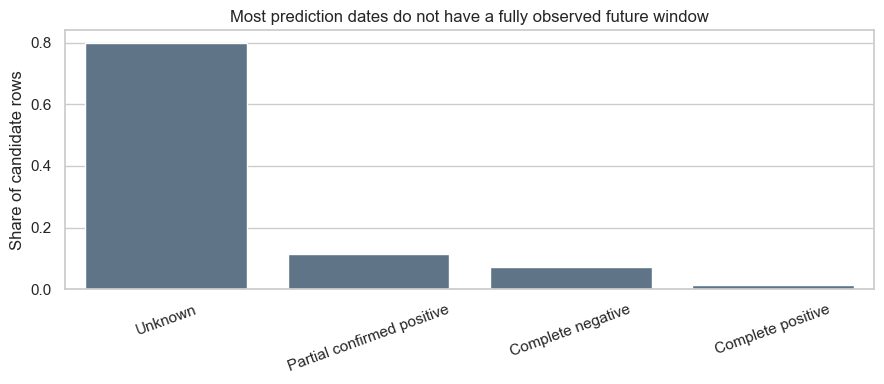

In [12]:
future_store = store_days[["date", "store_id", "is_reported"]].sort_values(["store_id", "date"])
for h in range(1, 8):
    future_store[f"reported_t{h}"] = future_store.groupby("store_id").is_reported.shift(-h)
future_store["future7_complete"] = future_store[[f"reported_t{h}" for h in range(1, 8)]].all(axis=1)

label_frame = sell_out[["date", "store_id", "sku_id", "is_out_of_stock"]].merge(
    future_store[["date", "store_id", "future7_complete"]], on=["date", "store_id"], how="left"
)
oos_index = sell_out.set_index(["date", "store_id", "sku_id"])["is_out_of_stock"]
any_future_oos = np.zeros(len(label_frame), dtype=bool)
for h in range(1, 8):
    idx = pd.MultiIndex.from_arrays([
        label_frame.date + pd.Timedelta(days=h), label_frame.store_id, label_frame.sku_id
    ])
    any_future_oos |= oos_index.reindex(idx, fill_value=False).to_numpy(dtype=bool)
label_frame["any_future_oos"] = any_future_oos
label_frame["label_status"] = np.select(
    [
        label_frame.future7_complete & label_frame.any_future_oos,
        label_frame.future7_complete & ~label_frame.any_future_oos,
        ~label_frame.future7_complete & label_frame.any_future_oos,
    ],
    ["Complete positive", "Complete negative", "Partial confirmed positive"],
    default="Unknown",
)
label_counts = label_frame.label_status.value_counts().rename_axis("label_status").to_frame("rows")
label_counts["share"] = label_counts.rows / label_counts.rows.sum()
display(label_counts)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=label_counts.reset_index(), x="label_status", y="share", color=COLORS["blue"], ax=ax)
ax.set(title="Most prediction dates do not have a fully observed future window", xlabel="", ylabel="Share of candidate rows")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### Label implication

Only about 8.5% of candidate rows have a complete future seven-day window. Another 11.6% are partial-window confirmed positives. Roughly 80% remain unknown. Formal validation and test metrics must use complete windows, while the team can compare training with and without partial confirmed positives.

### 6.2 A simple days-of-supply risk signal

,days_of_supply_bucket,rows,future7_oos_rate
0,<=1 day,3434,0.621
1,1-3 days,10905,0.381
2,3-7 days,30065,0.240
3,7-14 days,44877,0.058
4,>14 days,34504,0.007


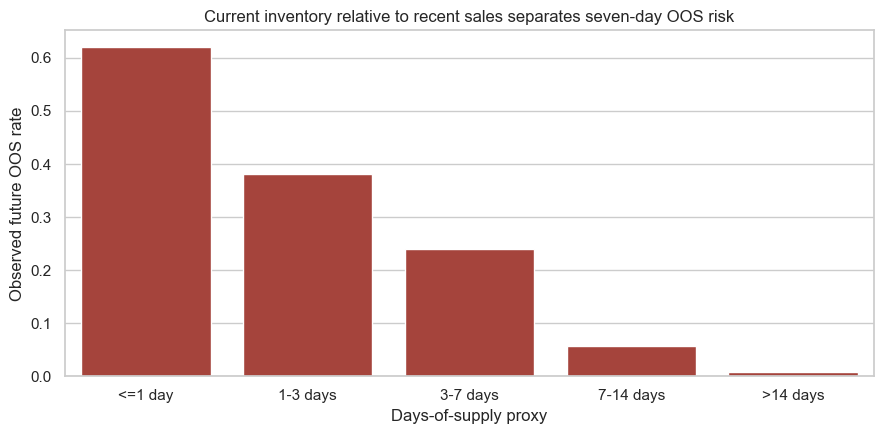

In [13]:
risk = sell_out.sort_values(["store_id", "sku_id", "date"]).copy()
risk["recent_sales_velocity"] = risk.groupby(["store_id", "sku_id"], observed=True).units_sold_daily.transform(
    lambda x: x.shift(1).rolling(7, min_periods=3).median()
)
risk["days_of_supply_proxy"] = risk.inventory_level / risk.recent_sales_velocity.replace(0, np.nan)
risk = risk.merge(
    label_frame[["date", "store_id", "sku_id", "future7_complete", "any_future_oos"]],
    on=["date", "store_id", "sku_id"], how="left", validate="one_to_one"
)
risk = risk.loc[risk.future7_complete & ~risk.is_out_of_stock].copy()
risk["days_of_supply_bucket"] = pd.cut(
    risk.days_of_supply_proxy,
    [-np.inf, 1, 3, 7, 14, np.inf],
    labels=["<=1 day", "1-3 days", "3-7 days", "7-14 days", ">14 days"]
)
risk_summary = risk.groupby("days_of_supply_bucket", observed=True).agg(
    rows=("sku_id", "size"), future7_oos_rate=("any_future_oos", "mean")
).reset_index()
display(risk_summary)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=risk_summary, x="days_of_supply_bucket", y="future7_oos_rate", color=COLORS["red"], ax=ax)
ax.set(title="Current inventory relative to recent sales separates seven-day OOS risk", xlabel="Days-of-supply proxy", ylabel="Observed future OOS rate")
plt.tight_layout()
plt.show()

### Product insight for Module 2

The simple inventory-to-velocity ratio already produces strong risk separation: complete-window rows with one day or less of supply have a future OOS rate above 60%, compared with below 1% above fourteen days. The model should improve on this signal, but the product should expose it because field representatives can understand it.

A transparent visit list can combine:

1. Current MSL OOS.
2. Seven-day OOS probability.
3. Units or trade value at risk.
4. Days of supply and the drivers of the prediction.
5. Last report date and whether the current state is observed or estimated.

## 7. MSL and shelf execution

In [14]:
msl_skus = products.loc[products.is_msl, "sku_id"]
retail_ids = stores.loc[stores.channel.ne("Distributor"), "store_id"]
msl = sell_out.loc[sell_out.store_id.isin(retail_ids) & sell_out.sku_id.isin(msl_skus)]
msl_day = msl.groupby(["date", "store_id"], observed=True).agg(
    observed_msl_skus=("sku_id", "nunique"),
    in_stock_msl_skus=("inventory_level", lambda x: int((x > 0).sum())),
).reset_index()
msl_day["global_msl_compliant"] = (
    msl_day.observed_msl_skus.eq(len(msl_skus)) & msl_day.in_stock_msl_skus.eq(len(msl_skus))
)
msl_day = msl_day.merge(stores[["store_id", "channel", "segment_tier"]], on="store_id", how="left")
msl_result = msl_day.groupby(["channel", "segment_tier"], observed=True).agg(
    observed_store_days=("date", "size"),
    full_msl_observation_rate=("observed_msl_skus", lambda x: (x == len(msl_skus)).mean()),
    global_msl_compliance=("global_msl_compliant", "mean"),
).reset_index()
display(msl_result)

,channel,segment_tier,observed_store_days,full_msl_observation_rate,global_msl_compliance
0,Modern Trade,Tier 1,15700,1.000,0.442
1,Modern Trade,Tier 2,13282,1.000,0.424
2,Modern Trade,Tier 3,9200,1.000,0.362
3,Traditional Trade,Tier 1,6076,1.000,0.442
4,Traditional Trade,Tier 2,14788,1.000,0.402
5,Traditional Trade,Tier 3,11413,1.000,0.309


### MSL finding

All 15 global MSL SKUs appear whenever a retail store reports, so the provisional KPI is measurable on observed store-days. Compliance is materially lower in Tier 3 than Tier 1. However, the business description says Tier 2 uses a selective assortment and Tier 3 a partial assortment. Until the client confirms tier-specific MSL mappings, the global KPI should be labeled as an assumption rather than a final performance score.

In [15]:
au = audits.merge(
    stores[["store_id", "channel", "segment_tier", "region"]], on="store_id", how="left", validate="many_to_one"
).merge(
    products[["sku_id", "category", "is_msl"]], on="sku_id", how="left", validate="many_to_one"
)

audit_kpis = au.groupby(["channel", "segment_tier"], observed=True).agg(
    audit_rows=("audit_id", "size"),
    planogram_compliance=("planogram_compliance", "mean"),
    secondary_display_rate=("secondary_display", "mean"),
    average_shelf_share_pct=("shelf_share_pct", "mean"),
).reset_index()
display(audit_kpis)

audit_store_days = au[["date", "store_id"]].drop_duplicates().sort_values(["store_id", "date"])
audit_store_days["days_since_prior_audit"] = audit_store_days.groupby("store_id").date.diff().dt.days
audit_cadence = audit_store_days.merge(
    stores[["store_id", "channel", "segment_tier"]], on="store_id", how="left"
).groupby(["channel", "segment_tier"], observed=True).days_since_prior_audit.agg(
    median_days="median", p95_days=lambda x: x.quantile(0.95), max_days="max"
).reset_index()
display(audit_cadence)

,channel,segment_tier,audit_rows,planogram_compliance,secondary_display_rate,average_shelf_share_pct
0,Distributor,Tier 1,24831,0.875,0.649,37.984
1,Distributor,Tier 2,7406,0.721,0.399,28.038
2,Distributor,Tier 3,3890,0.540,0.219,18.117
3,Modern Trade,Tier 1,67814,0.952,0.548,43.001
4,Modern Trade,Tier 2,27070,0.810,0.304,32.993
5,Modern Trade,Tier 3,8268,0.613,0.122,22.985
6,Traditional Trade,Tier 1,27007,0.873,0.554,38.015
7,Traditional Trade,Tier 2,30204,0.729,0.303,28.064
8,Traditional Trade,Tier 3,10530,0.529,0.122,18.024


,channel,segment_tier,median_days,p95_days,max_days
0,Distributor,Tier 1,7.000,9.000,9.000
1,Distributor,Tier 2,14.000,16.000,16.000
2,Distributor,Tier 3,28.000,30.000,30.000
3,Modern Trade,Tier 1,7.000,9.000,9.000
4,Modern Trade,Tier 2,14.000,16.000,16.000
5,Modern Trade,Tier 3,28.000,30.000,30.000
6,Traditional Trade,Tier 1,7.000,9.000,9.000
7,Traditional Trade,Tier 2,14.000,16.000,16.000
8,Traditional Trade,Tier 3,28.000,30.000,30.000


### Audit findings

- Audit cadence is clearly designed by tier: approximately 7 days for Tier 1, 14 days for Tier 2, and 28–30 days for Tier 3.
- Planogram compliance, secondary-display presence, and shelf share all decline with tier.
- This supports a tier-aware stale-audit rule, even though the final validity threshold still requires confirmation.

In [16]:
shelf_grain = au.groupby(["date", "store_id", "category"], observed=True).agg(
    sku_rows=("sku_id", "size"),
    unique_shelf_share_values=("shelf_share_pct", "nunique"),
    shelf_share_min=("shelf_share_pct", "min"),
    shelf_share_max=("shelf_share_pct", "max"),
).reset_index()

audit_sell = au.merge(
    sell_out[["date", "store_id", "sku_id", "units_sold_daily", "is_out_of_stock"]],
    on=["date", "store_id", "sku_id"], how="inner", validate="one_to_one"
)
audit_assoc = audit_sell.groupby(["planogram_compliance", "secondary_display"], observed=True).agg(
    rows=("audit_id", "size"),
    average_units_sold=("units_sold_daily", "mean"),
    oos_rate=("is_out_of_stock", "mean"),
    average_shelf_share=("shelf_share_pct", "mean"),
).reset_index()
display(audit_assoc)

print(f"Store-date-category groups: {len(shelf_grain):,}")
print(f"Groups with multiple shelf-share values: {(shelf_grain.unique_shelf_share_values > 1).mean():.1%}")

,planogram_compliance,secondary_display,rows,average_units_sold,oos_rate,average_shelf_share
0,False,False,16094,3.645,0.064,27.811
1,False,True,8399,5.237,0.055,33.352
2,True,False,64596,5.756,0.058,34.635
3,True,True,55815,7.025,0.054,38.317


Store-date-category groups: 30,480
Groups with multiple shelf-share values: 100.0%


### Shelf-execution interpretation

Rows with compliant planograms and secondary displays have higher same-day observed sales and lower OOS rates than rows with neither. This is useful for forming simulator assumptions, but it is not causal evidence: high-tier and high-volume stores are also more likely to execute well.

Every store-date-category group contains multiple shelf-share values across SKU rows. This contradicts a simple interpretation of the field as one Marvel category-level shelf share copied to each SKU. The product should avoid SKU-level shelf-share claims until the client confirms the grain and weighting rule.

## 8. Sell-in, negotiation guardrails, and replenishment evidence

,channel,category,invoices,median_effective_discount_pct,p95_effective_discount_pct,above_max_discount_rate,below_min_margin_rate
0,Distributor,Dishwashing,16152,6.979,11.497,0.000,0.000
1,Distributor,Laundry,20480,7.011,11.495,0.000,0.000
2,Distributor,Surface Cleaners,19063,7.005,11.491,0.000,0.000
3,Modern Trade,Dishwashing,45750,7.008,11.494,0.066,0.000
4,Modern Trade,Laundry,57189,7.003,11.500,0.000,0.000
5,Modern Trade,Surface Cleaners,53793,7.001,11.496,0.000,0.000
6,Traditional Trade,Dishwashing,19707,6.944,11.492,0.398,0.000
7,Traditional Trade,Laundry,23944,7.020,11.511,0.486,0.000
8,Traditional Trade,Surface Cleaners,21891,6.932,11.489,0.528,0.000


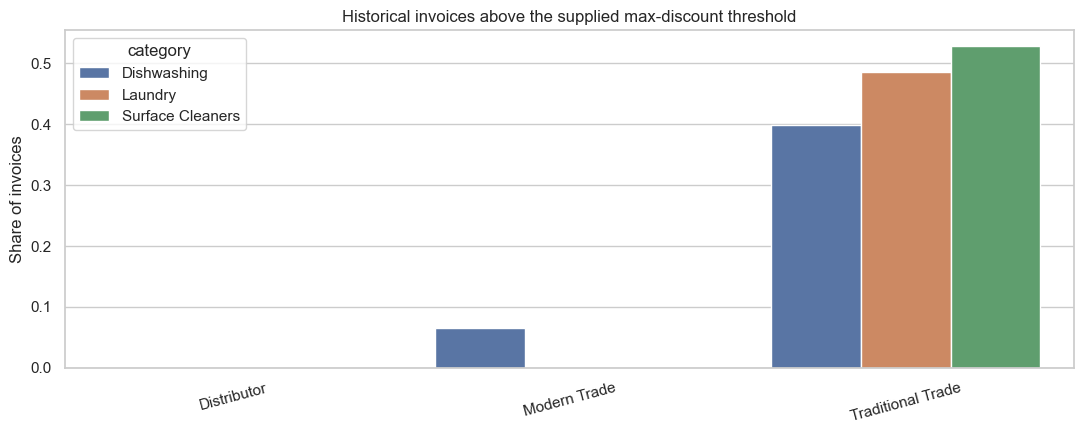

In [17]:
si = sell_in.merge(
    stores[["store_id", "channel", "segment_tier", "region"]], on="store_id", how="left", validate="many_to_one"
).merge(
    products[["sku_id", "category", "unit_cost", "list_price"]], on="sku_id", how="left", validate="many_to_one"
).merge(
    guardrails, on=["channel", "category"], how="left", validate="many_to_one"
)
si["invoice_unit_price"] = si.net_sales / si.units_sold
si["effective_discount_pct"] = 100 * (1 - si.invoice_unit_price / si.list_price)
si["gross_margin_pct"] = 100 * (si.invoice_unit_price - si.unit_cost) / si.invoice_unit_price
si["above_max_discount"] = si.effective_discount_pct > si.max_discount_pct
si["below_min_margin"] = si.gross_margin_pct < si.min_target_margin

guardrail_diag = si.groupby(["channel", "category"], observed=True).agg(
    invoices=("transaction_id", "size"),
    median_effective_discount_pct=("effective_discount_pct", "median"),
    p95_effective_discount_pct=("effective_discount_pct", lambda x: x.quantile(0.95)),
    above_max_discount_rate=("above_max_discount", "mean"),
    below_min_margin_rate=("below_min_margin", "mean"),
).reset_index()
display(guardrail_diag)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=guardrail_diag, x="channel", y="above_max_discount_rate", hue="category", ax=ax)
ax.set(title="Historical invoices above the supplied max-discount threshold", xlabel="", ylabel="Share of invoices")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### Negotiation findings

- About 12% of all invoices have an invoice-price-derived discount above the supplied `max_discount_pct`.
- The concentration is in Traditional Trade, where roughly 40%–53% of invoices exceed the threshold depending on category.
- No historical invoice falls below the supplied minimum margin floor.

These rows cannot automatically be called violations because the dataset does not record manager approval or accepted execution commitments. They demonstrate why Module 3 needs an explicit decision tree and why approval and commitment outcomes must be stored as new data.

### 8.1 Can Sell-in explain inventory replenishment?

,invoice_lag_days,inventory_increase_rate,lift_vs_baseline
0,0,0.050,-0.010
1,1,0.057,-0.003
2,2,0.059,-0.001
3,3,0.057,-0.004
4,4,0.057,-0.003
5,5,0.072,0.011
6,6,0.071,0.011
7,7,0.050,-0.010
8,8,0.057,-0.004
9,9,0.059,-0.002


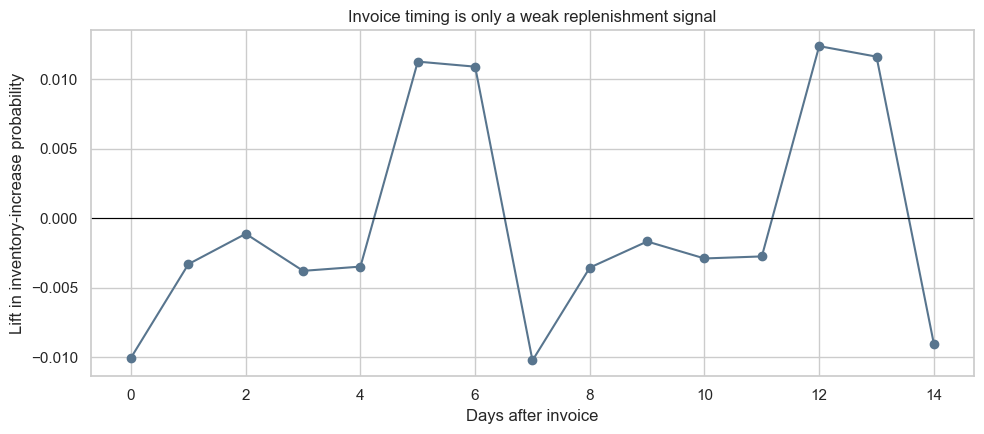

In [18]:
inv_daily = sell_out[["date", "store_id", "sku_id", "inventory_level"]].sort_values(["store_id", "sku_id", "date"])
inv_daily["prev_date"] = inv_daily.groupby(["store_id", "sku_id"]).date.shift(1)
inv_daily["prev_inventory"] = inv_daily.groupby(["store_id", "sku_id"]).inventory_level.shift(1)
inv_daily["calendar_gap"] = (inv_daily.date - inv_daily.prev_date).dt.days
inv_daily["inventory_increase"] = inv_daily.inventory_level - inv_daily.prev_inventory
inv_daily = inv_daily.loc[inv_daily.calendar_gap.eq(1)].copy()

invoice_daily = sell_in.groupby(["date", "store_id", "sku_id"], observed=True).units_sold.sum().rename("invoice_units")
baseline_jump_rate = inv_daily.inventory_increase.gt(0).mean()
lag_rows = []
for lag in range(15):
    idx = pd.MultiIndex.from_arrays([
        inv_daily.date - pd.Timedelta(days=lag), inv_daily.store_id, inv_daily.sku_id
    ])
    signal = invoice_daily.reindex(idx, fill_value=0).to_numpy() > 0
    lag_rows.append({
        "invoice_lag_days": lag,
        "inventory_increase_rate": inv_daily.loc[signal, "inventory_increase"].gt(0).mean(),
        "lift_vs_baseline": inv_daily.loc[signal, "inventory_increase"].gt(0).mean() - baseline_jump_rate,
    })
lag_effect = pd.DataFrame(lag_rows)
display(lag_effect)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(lag_effect.invoice_lag_days, lag_effect.lift_vs_baseline, marker="o", color=COLORS["blue"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Invoice timing is only a weak replenishment signal", xlabel="Days after invoice", ylabel="Lift in inventory-increase probability")
plt.tight_layout()
plt.show()

### Replenishment finding

Inventory increases are slightly more common five to six days and twelve to thirteen days after an invoice, but the lift is only about one percentage point. Sell-in can be used as a lagged feature, but it is not strong enough to add invoiced units directly to inventory. This supports the existing policy that invoice date is not receipt date.

### 8.2 Sell-in versus Sell-out sensitivity

,sell_in_units,sell_out_observed_units,sell_out_coverage_scaled_units
channel,,,
Distributor,1458519,"1,319,943.000","1,904,370.446"
Modern Trade,5029653,"4,536,443.000","6,486,916.918"
Traditional Trade,1069055,"1,949,260.000","2,802,703.406"


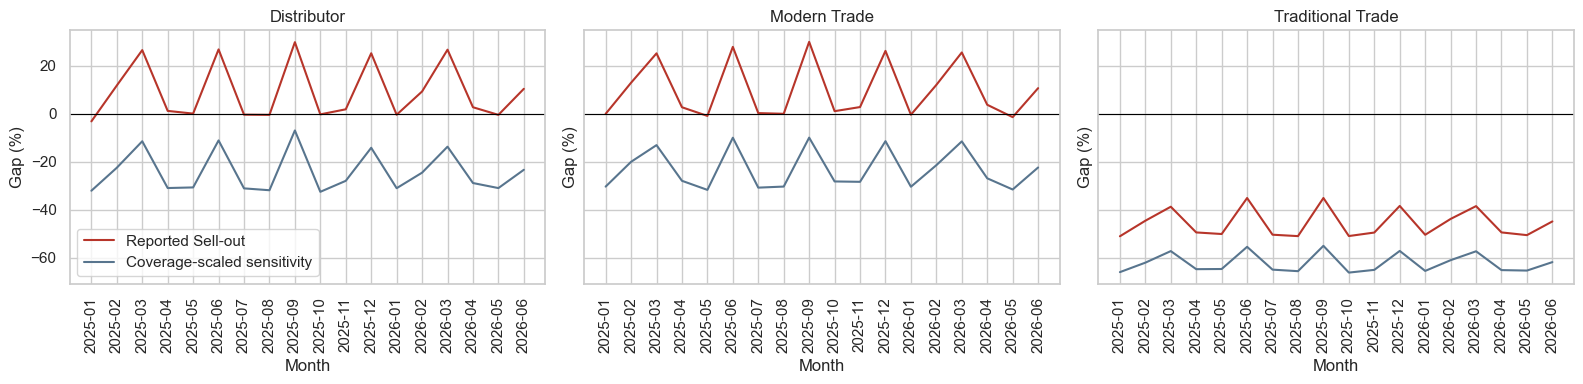

In [19]:
si_month = si.assign(month=si.date.dt.to_period("M").astype(str)).groupby(["month", "channel"], observed=True).units_sold.sum().rename("sell_in_units")
so_month = so.assign(month=so.date.dt.to_period("M").astype(str)).groupby(["month", "channel"], observed=True).units_sold_daily.sum().rename("sell_out_observed_units")
month_coverage = store_days.groupby(["month", "channel"], observed=True).is_reported.mean().rename("coverage")
flow = pd.concat([si_month, so_month, month_coverage], axis=1).reset_index()
flow["sell_out_coverage_scaled_units"] = flow.sell_out_observed_units / flow.coverage
flow["gap_observed_pct"] = 100 * (flow.sell_in_units - flow.sell_out_observed_units) / flow.sell_out_observed_units
flow["gap_coverage_scaled_pct"] = 100 * (flow.sell_in_units - flow.sell_out_coverage_scaled_units) / flow.sell_out_coverage_scaled_units

display(flow.groupby("channel")[["sell_in_units", "sell_out_observed_units", "sell_out_coverage_scaled_units"]].sum())

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, channel in zip(axes, flow.channel.unique()):
    g = flow.loc[flow.channel.eq(channel)]
    ax.plot(g.month, g.gap_observed_pct, label="Reported Sell-out", color=COLORS["red"])
    ax.plot(g.month, g.gap_coverage_scaled_pct, label="Coverage-scaled sensitivity", color=COLORS["blue"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=channel, xlabel="Month", ylabel="Gap (%)")
    ax.tick_params(axis="x", rotation=90)
axes[0].legend()
plt.tight_layout()
plt.show()

### Flow-gap interpretation

Observed Sell-out understates downstream flow because 30% of store-days are absent. A simple coverage-scaled sensitivity materially changes the gap, so the dashboard should show both the reported and estimated versions with coverage. Traditional Trade remains strongly negative under either view, which is a real analytical issue rather than only a missing-data artifact. The gap is a flow imbalance signal, not an inventory equation.

## 9. Distributor treatment

In [20]:
channel_summary = so.groupby("channel", observed=True).agg(
    accounts=("store_id", "nunique"),
    observed_rows=("date", "size"),
    units_sold=("units_sold_daily", "sum"),
    average_daily_units=("units_sold_daily", "mean"),
    oos_rate=("is_out_of_stock", "mean"),
    average_inventory=("inventory_level", "mean"),
).reset_index()
active_by_channel = so[["channel", "store_id", "sku_id"]].drop_duplicates().groupby("channel").size()
channel_summary["active_store_sku_pairs"] = channel_summary.channel.map(active_by_channel)
channel_summary["store_day_coverage"] = channel_summary.channel.map(store_days.groupby("channel").is_reported.mean())
display(channel_summary)

distributor_audits = au.loc[au.channel.eq("Distributor")]
print(f"Distributor Sell-out rows: {(so.channel == 'Distributor').sum():,}")
print(f"Distributor audit rows using retail execution fields: {len(distributor_audits):,}")

,channel,accounts,observed_rows,units_sold,average_daily_units,oos_rate,average_inventory,active_store_sku_pairs,store_day_coverage
0,Distributor,36,267568,1319943,4.933,0.057,47.664,707,0.693
1,Modern Trade,100,758647,4536443,5.980,0.058,57.920,1987,0.699
2,Traditional Trade,85,630541,1949260,3.091,0.064,29.704,1661,0.695


Distributor Sell-out rows: 267,568
Distributor audit rows using retail execution fields: 36,127


### Distributor product decision

Distributor data is structurally complete enough to analyze, but its business meaning differs. The supplied records assign OOS, consumer-style Sell-out, planogram, shelf share, and secondary displays to wholesale accounts. This is internally consistent synthetic data, not proof that the same retail workflow is appropriate.

Recommended treatment:

- Exclude Distributor accounts from retail MSL, planogram, shelf-share, store-visit, and consumer OOS KPIs.
- Retain a separately labeled wholesale flow view while the meaning of Distributor Sell-out is confirmed.
- Build a Distributor negotiation mode around volume, invoice price, margin, and approval authority.
- Replace retail shelf commitments only after the client confirms volume thresholds.

## 10. Latest operational state on June 30, 2026

In [21]:
latest = sell_out.sort_values("date").groupby(["store_id", "sku_id"], observed=True).tail(1).copy()
latest["days_since_inventory_report"] = (end_date - latest.date).dt.days
latest_summary = pd.Series({
    "Active store-SKU pairs": len(latest),
    "Pairs observed on June 30": latest.days_since_inventory_report.eq(0).sum(),
    "Median days since report": latest.days_since_inventory_report.median(),
    "95th percentile days since report": latest.days_since_inventory_report.quantile(0.95),
    "Maximum days since report": latest.days_since_inventory_report.max(),
    "Latest-known OOS rate": latest.is_out_of_stock.mean(),
})
display(latest_summary.to_frame("value"))

,value
Active store-SKU pairs,"4,355.000"
Pairs observed on June 30,"3,040.000"
Median days since report,0.000
95th percentile days since report,2.000
Maximum days since report,6.000
Latest-known OOS rate,0.056


### Product implication

The latest-known state is generally fresh: the median report age is zero days, the 95th percentile is two days, and the maximum is six days. The application can default to an estimated operational view, but each row should show `Observed`, `Estimated`, or `Unknown` and the last reporting date. A separate Reported Data Only view should remain available for verification.

## 11. Product design insights by module

### Module 1: Commercial execution analytics

- Show data coverage with every period KPI.
- Default to an operational estimate, with a Reported Data Only toggle.
- Treat MSL compliance as provisional until the required assortment by tier is confirmed.
- Use actual audits for official period KPIs and latest prior audits for current status.
- Make shelf-execution gaps actionable: missing MSL SKU, planogram status, shelf share, display status, audit date, and recommended visit objective.
- Keep Distributor accounts out of retail execution KPIs.

### Module 2: OOS risk and visit planning

- Use a daily store-SKU analytical mart with past-only inventory, sales velocity, Sell-in signals, audit features, and data-state flags.
- Keep current OOS separate from predicted future risk.
- Expose days of supply and other understandable risk drivers.
- Evaluate only on complete future windows; compare training with and without partial confirmed positives.
- Rank stores using current MSL OOS first, then expected value or units at risk, with data freshness visible.

### Module 3: Negotiation simulator

- Calculate discount from Marvel trade list price and margin from net trade price.
- Require a configurable approval tree because historical invoices often exceed the supplied discount threshold while remaining above the margin floor.
- Store the proposed discount, calculated margin, execution commitment, approval status, approver, and later audit result.
- Use a separate Distributor mode based on volume commitments.
- Treat execution uplift as an observational scenario assumption until a controlled causal method is available.

### Module 4: Commercial copilot

- Answer from governed KPI and analytical tables instead of raw fact-table joins.
- State whether a value is reported, estimated, or unknown.
- Surface the last report and latest audit dates.
- Explain why a store or SKU is prioritized using the same drivers shown in Module 2.
- Avoid unsupported claims about consumer price elasticity, causal execution uplift, and Distributor retail execution.

## 12. Recommended data-development sequence

1. Create tested dimension and fact staging tables without altering raw data.
2. Build the complete active store-SKU calendar and observation flags.
3. Implement the time-based masked-store-day experiment harness.
4. Select separate sales and inventory estimation methods and an `Unknown` cutoff.
5. Build `mart_store_sku_daily` with observed and estimated fields kept separate.
6. Construct seven-day OOS labels and chronological train, validation, and test splits with a seven-day purge gap.
7. Build retail execution KPIs and a separate wholesale view.
8. Implement the configurable negotiation decision tree after client confirmation.
9. Add product monitoring for coverage, estimation error, label eligibility, model performance, and KPI changes caused by estimation.

## 13. Remaining client decisions

1. Should required MSL assortments differ by channel or tier?
2. What is the complete discount authority, commitment, approval, and margin-floor decision tree?
3. Should Distributor retail conditions be replaced by volume commitments, and what are the thresholds?
4. Does `shelf_share_pct` describe SKU share or Marvel category share, and how should it be weighted?
5. Should audit validity use tier cadence, a fixed number of days, or remain visible without a validity claim?
6. Is invoice-to-delivery timing available by channel?
7. Should value at risk use units, trade list value, expected invoice value, or gross-margin contribution?

These decisions change product behavior. The team can begin the data experiments before they are resolved, but the unresolved assumptions must remain configurable and visible.

# 14. Formal Missing Store-Day Sales Imputation Experiment

This experiment evaluates whether observed sales can be reconstructed when a complete account-day report is absent. It operates on an in-memory copy and does not modify the raw CSV files.

The experiment preserves the agreed rules:

1. The masking unit is one account-day and all active SKUs for that account.
2. Consecutive mask lengths follow the empirical missing-run distribution.
3. Validation uses May 2026 with history through April 30.
4. Final testing uses June 2026 with history through May 31.
5. Predictions use only information available before the evaluation period.
6. Sales and inventory remain separate experiments. This section evaluates sales only.


## 14.1 Build realistic store-day masks

The source data loses complete store-day reports rather than isolated cells. The mask generator therefore hides every active SKU for a selected account-day. It samples one-day, two-day, and longer blocks in the same proportions found in the observed reporting gaps.

The artificial masking rate is applied only to originally observed store-days with known answers. Existing real missing days remain excluded from scoring because their true sales are unknown.


In [22]:
from pathlib import Path

import numpy as np
import pandas as pd


DATA_DIR = DATA

stores = pd.read_csv(DATA_DIR / "dim_stores.csv")
products = pd.read_csv(DATA_DIR / "dim_products.csv")
sell_out = pd.read_csv(DATA_DIR / "fact_sell_out.csv", parse_dates=["date"])

so = sell_out.merge(
    stores[["store_id", "channel", "segment_tier", "region"]],
    on="store_id",
    how="left",
    validate="many_to_one",
).merge(
    products[["sku_id", "category", "is_msl"]],
    on="sku_id",
    how="left",
    validate="many_to_one",
)
so["weekday"] = so["date"].dt.dayofweek

active_pairs = so[["store_id", "sku_id"]].drop_duplicates()
active_skus = active_pairs.groupby("store_id").size().rename("active_skus")


def run_lengths(mask):
    padded = np.r_[False, mask, False].astype(np.int8)
    changes = np.diff(padded)
    return np.flatnonzero(changes == -1) - np.flatnonzero(changes == 1)


calendar = pd.MultiIndex.from_product(
    [pd.date_range(so["date"].min(), so["date"].max(), freq="D"), stores["store_id"]],
    names=["date", "store_id"],
).to_frame(index=False)
reported_days = so[["date", "store_id"]].drop_duplicates().assign(is_reported=True)
calendar = calendar.merge(reported_days, on=["date", "store_id"], how="left")
calendar["is_reported"] = calendar["is_reported"].eq(True)

all_missing_runs = []
for _, group in calendar.sort_values("date").groupby("store_id", sort=False):
    all_missing_runs.extend(run_lengths((~group["is_reported"]).to_numpy()))
run_probability = pd.Series(all_missing_runs).value_counts(normalize=True).sort_index()


def allocate_block_counts(target_days, probabilities):
    mean_length = float(sum(length * probability for length, probability in probabilities.items()))
    target_blocks = max(1, round(target_days / mean_length))
    raw = probabilities * target_blocks
    counts = np.floor(raw).astype(int)
    remainder = target_blocks - int(counts.sum())
    if remainder:
        for length in (raw - counts).sort_values(ascending=False).head(remainder).index:
            counts.loc[length] += 1
    return counts


def create_store_day_masks(start, end, seed, mask_fraction=0.3032):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)
    period_reported = reported_days.loc[
        reported_days["date"].between(start, end), ["date", "store_id"]
    ].copy()
    target_days = round(len(period_reported) * mask_fraction)
    desired_blocks = allocate_block_counts(target_days, run_probability)
    observed_by_store = {
        store_id: set(group["date"])
        for store_id, group in period_reported.groupby("store_id", sort=False)
    }
    rng = np.random.default_rng(seed)
    used = set()
    blocks = []
    block_id = 0

    for length in sorted(desired_blocks.index, reverse=True):
        wanted = int(desired_blocks.loc[length])
        if wanted == 0:
            continue
        candidates = []
        for store_id, observed_dates in observed_by_store.items():
            for first_date in sorted(observed_dates):
                dates = tuple(first_date + pd.Timedelta(days=offset) for offset in range(int(length)))
                if dates[-1] <= end and all(date in observed_dates for date in dates):
                    candidates.append((store_id, dates))
        rng.shuffle(candidates)
        accepted = 0
        for store_id, dates in candidates:
            keys = {(store_id, date) for date in dates}
            buffered_keys = {
                (store_id, date + pd.Timedelta(days=offset))
                for date in dates
                for offset in (-1, 0, 1)
            }
            if buffered_keys & used:
                continue
            block_id += 1
            for date in dates:
                blocks.append({
                    "store_id": store_id,
                    "date": date,
                    "mask_block_id": block_id,
                    "mask_block_length": int(length),
                })
            used.update(keys)
            accepted += 1
            if accepted >= wanted:
                break

    # Remove a small rounding excess using one-day blocks, preserving longer episodes.
    if len(blocks) > target_days:
        excess = len(blocks) - target_days
        one_day_ids = [
            block["mask_block_id"]
            for block in blocks
            if block["mask_block_length"] == 1
        ][:excess]
        one_day_ids = set(one_day_ids)
        blocks = [block for block in blocks if block["mask_block_id"] not in one_day_ids]

    # Fill any small day-count shortfall with non-overlapping one-day blocks.
    if len(blocks) < target_days:
        occupied = {(block["store_id"], block["date"]) for block in blocks}
        remaining = [
            (row.store_id, row.date)
            for row in period_reported.itertuples(index=False)
            if not any(
                (row.store_id, row.date + pd.Timedelta(days=offset)) in occupied
                for offset in (-1, 0, 1)
            )
        ]
        rng.shuffle(remaining)
        for store_id, date in remaining:
            if any(
                (store_id, date + pd.Timedelta(days=offset)) in occupied
                for offset in (-1, 0, 1)
            ):
                continue
            block_id += 1
            blocks.append({
                "store_id": store_id,
                "date": date,
                "mask_block_id": block_id,
                "mask_block_length": 1,
            })
            occupied.add((store_id, date))
            if len(blocks) >= target_days:
                break

    masks = pd.DataFrame(blocks).sort_values(["store_id", "date"]).reset_index(drop=True)
    if masks.duplicated(["store_id", "date"]).any():
        raise AssertionError("Mask generator produced duplicate store-days.")
    if len(masks) != target_days:
        raise AssertionError(f"Expected {target_days} masked store-days but created {len(masks)}.")
    return masks, len(period_reported)


def map_multi(series, frame, columns):
    index = pd.MultiIndex.from_frame(frame[columns])
    return series.reindex(index).to_numpy(dtype=float)


def fit_predict_sales(history, targets, cutoff, half_life_days=28):
    train = history.loc[(history["date"] <= cutoff) & ~history["is_out_of_stock"]].copy()
    target = targets.copy()

    store_sku_weekday = train.groupby(
        ["store_id", "sku_id", "weekday"], observed=True
    )["units_sold_daily"].median()
    store_sku = train.groupby(["store_id", "sku_id"], observed=True)["units_sold_daily"].median()
    tier_sku_weekday = train.groupby(
        ["channel", "segment_tier", "sku_id", "weekday"], observed=True
    )["units_sold_daily"].median()
    channel_sku_weekday = train.groupby(
        ["channel", "sku_id", "weekday"], observed=True
    )["units_sold_daily"].median()
    category_tier_weekday = train.groupby(
        ["category", "segment_tier", "weekday"], observed=True
    )["units_sold_daily"].median()
    overall = float(train["units_sold_daily"].median())

    p1 = map_multi(store_sku_weekday, target, ["store_id", "sku_id", "weekday"])
    p2 = map_multi(store_sku, target, ["store_id", "sku_id"])
    p3 = map_multi(tier_sku_weekday, target, ["channel", "segment_tier", "sku_id", "weekday"])
    p4 = map_multi(channel_sku_weekday, target, ["channel", "sku_id", "weekday"])
    p5 = map_multi(category_tier_weekday, target, ["category", "segment_tier", "weekday"])

    hierarchical = np.where(
        np.isfinite(p1), p1,
        np.where(
            np.isfinite(p2), p2,
            np.where(np.isfinite(p3), p3, np.where(np.isfinite(p4), p4, p5)),
        ),
    )
    hierarchical = np.where(np.isfinite(hierarchical), hierarchical, overall)

    age_days = (pd.Timestamp(cutoff) - train["date"]).dt.days.clip(lower=0)
    train["recency_weight"] = np.power(0.5, age_days / half_life_days)
    train["weighted_units"] = train["units_sold_daily"] * train["recency_weight"]
    recency = train.groupby(["store_id", "sku_id"], observed=True).agg(
        weighted_units=("weighted_units", "sum"),
        total_weight=("recency_weight", "sum"),
    )
    recency["prediction"] = recency["weighted_units"] / recency["total_weight"]
    recency_prediction = map_multi(recency["prediction"], target, ["store_id", "sku_id"])

    target["zero_fill"] = 0.0
    target["store_sku_median"] = np.where(np.isfinite(p2), p2, hierarchical)
    target["store_sku_weekday_median"] = np.where(np.isfinite(p1), p1, np.where(np.isfinite(p2), p2, hierarchical))
    target["hierarchical_fallback"] = hierarchical
    target["recency_weighted_average"] = np.where(
        np.isfinite(recency_prediction), recency_prediction, hierarchical
    )
    return target


METHODS = [
    "zero_fill",
    "store_sku_median",
    "store_sku_weekday_median",
    "hierarchical_fallback",
    "recency_weighted_average",
]


def score_group(group, method):
    error = group[method] - group["units_sold_daily"]
    denominator = group["units_sold_daily"].abs().sum()
    return {
        "rows": len(group),
        "MAE": error.abs().mean(),
        "WAPE": error.abs().sum() / denominator if denominator else np.nan,
        "Bias": error.mean(),
    }


def score_predictions(frame, split):
    return pd.DataFrame([
        {"split": split, "method": method, **score_group(frame, method)}
        for method in METHODS
    ])


def run_split(split, start, end, history_cutoff, seed):
    masks, observed_store_days = create_store_day_masks(start, end, seed)
    targets = so.loc[so["date"].between(start, end)].merge(
        masks,
        on=["date", "store_id"],
        how="inner",
        validate="many_to_one",
    )
    expected_rows = targets[["store_id", "date"]].drop_duplicates().merge(
        active_skus,
        on="store_id",
        how="left",
        validate="many_to_one",
    )["active_skus"].sum()
    if len(targets) != expected_rows:
        raise AssertionError("At least one masked store-day does not contain its full active assortment.")
    predictions = fit_predict_sales(so, targets, pd.Timestamp(history_cutoff))
    summary = {
        "split": split,
        "observed_store_days": observed_store_days,
        "masked_store_days": len(masks),
        "artificial_mask_rate": len(masks) / observed_store_days,
        "masked_sku_rows": len(targets),
        "complete_store_day_mask_rate": 1.0,
        "maximum_mask_block_length": masks["mask_block_length"].max(),
    }
    return predictions, summary, masks


validation_predictions, validation_mask_summary, validation_masks = run_split(
    "Validation", "2026-05-01", "2026-05-31", "2026-04-30", 650
)
test_predictions, test_mask_summary, test_masks = run_split(
    "Test", "2026-06-01", "2026-06-30", "2026-05-31", 651
)

experiment_scores = pd.concat([
    score_predictions(validation_predictions, "Validation"),
    score_predictions(test_predictions, "Test"),
], ignore_index=True)

test_channel_scores = pd.DataFrame([
    {"channel": channel, "method": method, **score_group(group, method)}
    for channel, group in test_predictions.groupby("channel", observed=True)
    for method in METHODS[1:]
])

test_gap_scores = pd.DataFrame([
    {"mask_block_length": int(length), "method": method, **score_group(group, method)}
    for length, group in test_predictions.groupby("mask_block_length", observed=True)
    for method in METHODS[1:]
])

test_oos_scores = pd.DataFrame([
    {"actual_oos": bool(oos), "method": method, **score_group(group, method)}
    for oos, group in test_predictions.groupby("is_out_of_stock", observed=True)
    for method in METHODS[1:]
])

In [23]:
formal_mask_summary = pd.DataFrame([validation_mask_summary, test_mask_summary])
display(formal_mask_summary)

formal_block_distribution = pd.concat({
    "Validation masks": validation_masks.groupby("mask_block_id")["mask_block_length"].first().value_counts(normalize=True).sort_index(),
    "Test masks": test_masks.groupby("mask_block_id")["mask_block_length"].first().value_counts(normalize=True).sort_index(),
    "Observed missing runs": run_probability,
}, axis=1).fillna(0)
display(formal_block_distribution)

formal_mask_checks = pd.Series({
    "Validation store-days masked as complete blocks": validation_mask_summary["complete_store_day_mask_rate"],
    "Test store-days masked as complete blocks": test_mask_summary["complete_store_day_mask_rate"],
    "Validation duplicate masked store-days": validation_masks.duplicated(["store_id", "date"]).sum(),
    "Test duplicate masked store-days": test_masks.duplicated(["store_id", "date"]).sum(),
    "Raw Sell-out rows modified": 0,
})
display(formal_mask_checks.to_frame("value"))

,split,observed_store_days,masked_store_days,artificial_mask_rate,masked_sku_rows,complete_store_day_mask_rate,maximum_mask_block_length
0,Validation,4774,1447,0.303,28459,1.000,7
1,Test,4620,1401,0.303,27539,1.000,6


,Validation masks,Test masks,Observed missing runs
1,0.698,0.699,0.698
2,0.211,0.210,0.211
3,0.063,0.063,0.064
4,0.019,0.019,0.019
5,0.006,0.006,0.006
6,0.002,0.002,0.002
7,0.001,0.000,0.000
8,0.000,0.000,0.000
10,0.000,0.000,0.000


,value
Validation store-days masked as complete blocks,1.000
Test store-days masked as complete blocks,1.000
Validation duplicate masked store-days,0.000
Test duplicate masked store-days,0.000
Raw Sell-out rows modified,0.000


### Mask validation

- Approximately 30.3% of the originally observed store-days are hidden in both validation and test.
- Every selected store-day contains the account's complete active assortment before masking.
- The artificial block-length distribution closely matches the observed missing-run distribution.
- Long gaps are naturally rare. Results for six or more consecutive days have much smaller samples and should not determine the operating rule by themselves.


## 14.2 Compare sales-imputation methods

The methods are deliberately explainable baselines:

1. `zero_fill`: negative control.
2. `store_sku_median`: historical in-stock median for the same account and SKU.
3. `store_sku_weekday_median`: same account and SKU, conditioned on weekday, with a store-SKU fallback.
4. `hierarchical_fallback`: progressively broader account, tier, channel, SKU, category, and weekday groups when detailed history is unavailable.
5. `recency_weighted_average`: recent in-stock observations receive more weight using a 28-day half-life.

The model-selection decision uses validation WAPE first, then MAE and absolute bias. The June test result is reported only after that selection rule is applied.


,split,method,rows,MAE,WAPE,Bias
0,Validation,zero_fill,28459,4.971,1.000,-4.971
1,Validation,store_sku_median,28459,1.984,0.399,-0.158
2,Validation,store_sku_weekday_median,28459,1.956,0.393,-0.079
3,Validation,hierarchical_fallback,28459,1.956,0.393,-0.079
4,Validation,recency_weighted_average,28459,2.034,0.409,0.261
5,Test,zero_fill,27539,4.356,1.000,-4.356
6,Test,store_sku_median,27539,1.816,0.417,0.337
7,Test,store_sku_weekday_median,27539,1.808,0.415,0.374
8,Test,hierarchical_fallback,27539,1.808,0.415,0.374
9,Test,recency_weighted_average,27539,1.930,0.443,0.699


,value
Validation-selected method,store_sku_weekday_median
Validation WAPE,0.393
Validation MAE,1.956
Validation Bias,-0.079
Test WAPE,0.415
Test MAE,1.808
Test Bias,0.374


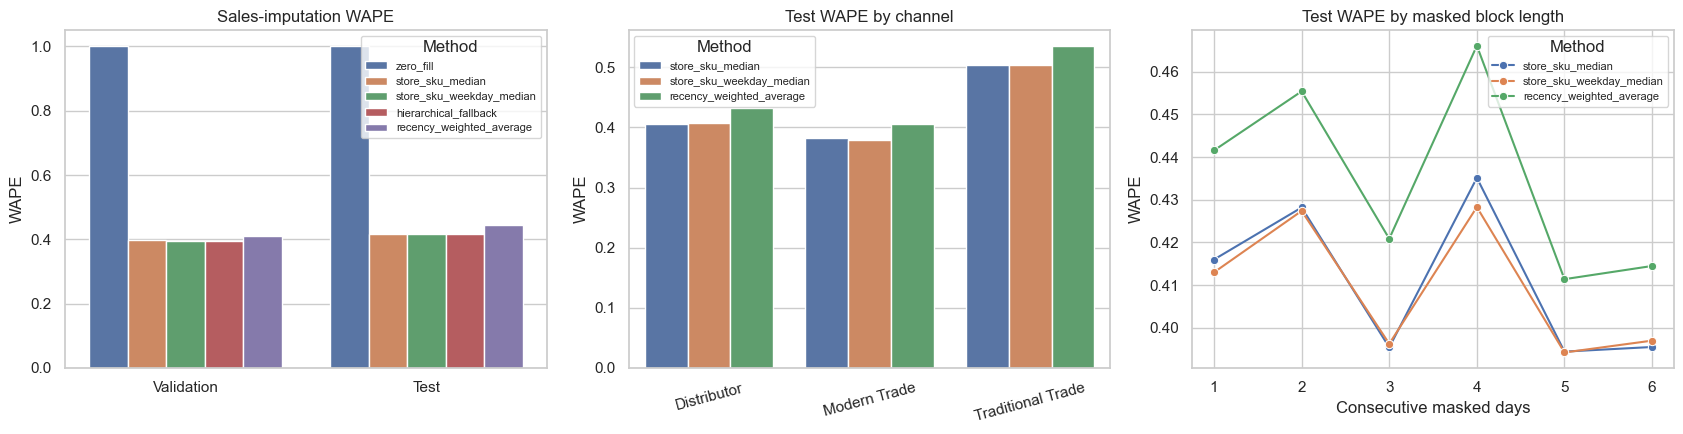

,channel,method,rows,MAE,WAPE,Bias
5,Modern Trade,store_sku_weekday_median,12230,2.076,0.378,0.514
1,Distributor,store_sku_weekday_median,4925,1.906,0.407,0.435
9,Traditional Trade,store_sku_weekday_median,10384,1.446,0.504,0.180


,actual_oos,method,rows,MAE,WAPE,Bias
1,False,store_sku_weekday_median,25988,1.705,0.375,0.208
5,True,store_sku_weekday_median,1551,3.533,3.028,3.155


In [24]:
formal_score_display = experiment_scores.copy()
display(formal_score_display)

candidate_validation = experiment_scores.loc[
    (experiment_scores["split"] == "Validation")
    & (experiment_scores["method"] != "zero_fill")
].sort_values(["WAPE", "MAE", "Bias"], key=lambda column: column.abs() if column.name == "Bias" else column)
selected_sales_method = candidate_validation.iloc[0]["method"]

formal_decision = pd.Series({
    "Validation-selected method": selected_sales_method,
    "Validation WAPE": candidate_validation.iloc[0]["WAPE"],
    "Validation MAE": candidate_validation.iloc[0]["MAE"],
    "Validation Bias": candidate_validation.iloc[0]["Bias"],
    "Test WAPE": experiment_scores.loc[
        (experiment_scores["split"] == "Test")
        & (experiment_scores["method"] == selected_sales_method), "WAPE"
    ].iloc[0],
    "Test MAE": experiment_scores.loc[
        (experiment_scores["split"] == "Test")
        & (experiment_scores["method"] == selected_sales_method), "MAE"
    ].iloc[0],
    "Test Bias": experiment_scores.loc[
        (experiment_scores["split"] == "Test")
        & (experiment_scores["method"] == selected_sales_method), "Bias"
    ].iloc[0],
})
display(formal_decision.to_frame("value"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.barplot(
    data=experiment_scores,
    x="split", y="WAPE", hue="method", ax=axes[0]
)
axes[0].set(title="Sales-imputation WAPE", xlabel="", ylabel="WAPE")
axes[0].legend(title="Method", fontsize=8)

sns.barplot(
    data=test_channel_scores.loc[test_channel_scores["method"].isin([
        "store_sku_median", "store_sku_weekday_median", "recency_weighted_average"
    ])],
    x="channel", y="WAPE", hue="method", ax=axes[1]
)
axes[1].set(title="Test WAPE by channel", xlabel="", ylabel="WAPE")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Method", fontsize=8)

sns.lineplot(
    data=test_gap_scores.loc[test_gap_scores["method"].isin([
        "store_sku_median", "store_sku_weekday_median", "recency_weighted_average"
    ])],
    x="mask_block_length", y="WAPE", hue="method", marker="o", ax=axes[2]
)
axes[2].set(title="Test WAPE by masked block length", xlabel="Consecutive masked days", ylabel="WAPE")
axes[2].legend(title="Method", fontsize=8)
plt.tight_layout()
plt.show()

display(
    test_channel_scores.loc[test_channel_scores["method"] == selected_sales_method]
    .sort_values("WAPE")
)
display(
    test_oos_scores.loc[test_oos_scores["method"] == selected_sales_method]
    .sort_values("actual_oos")
)

### Sales-imputation findings

- Zero fill produces 100% WAPE and remains invalid for missing reports.
- The store-SKU-weekday median and hierarchical fallback tie at about 39.3% validation WAPE and 41.5% test WAPE. They tie because the long training history supplies the most detailed store-SKU-weekday group for nearly every target row. The fallback remains necessary for future new stores, SKUs, or sparse groups.
- The plain store-SKU median is only slightly worse, at about 41.7% test WAPE.
- The recency-weighted average is worse and has a larger positive bias. Recent sales were not stable enough for the selected 28-day weighting to improve this dataset.
- Traditional Trade is the hardest channel, at about 50.0% WAPE for the selected method. Modern Trade is lowest at about 38.0%.
- Error does not rise consistently from one- to five-day blocks because these static sales baselines predict daily flow independently. The later inventory experiment will accumulate daily errors across the block and is expected to be much more sensitive to gap length.
- Sales on actual OOS rows are substantially overestimated. The methods learn normal in-stock velocity, while observed OOS sales are inventory-constrained. This is evidence that sales imputation alone cannot recover OOS state. The next inventory experiment must use the last known inventory and replenishment signals.

**Provisional sales method:** use the store-SKU-weekday median with hierarchical fallback for the explainable MVP baseline. Keep the plain store-SKU median as a robustness check. Do not treat this decision as final until the inventory and downstream OOS-impact experiments are complete.


## 14.3 Next experiment

Use the provisional sales estimates inside a separate inventory-state experiment. Compare last observation, depletion, hybrid, replenishment-aware, and lagged Sell-in-assisted methods. Evaluate inventory error, OOS classification, gap-length stability, channel stability, and downstream store ranking.


# 15. Formal Missing Store-Day Inventory Experiment

This experiment reuses the realistic validation and test masks from Section 14. For every hidden account-day block and SKU, it starts from the latest previously reported inventory and estimates each missing day sequentially. No future inventory observation is used to initialize or update a prediction.

Inventory is a state, so errors accumulate across consecutive missing days. The experiment evaluates both inventory reconstruction and whether the reconstructed state correctly identifies OOS.


## 15.1 Validate the stock-flow relationship and replenishment signal

For consecutive observed days, the implied receipt quantity is:

`receipt_t = inventory_t - inventory_(t-1) + units_sold_t`

A zero residual means that the prior inventory minus sales fully explains the current inventory. A positive residual is treated as an inferred replenishment. Negative residuals would indicate that the simple balance equation is incomplete or inconsistent.

Sell-in is tested only as a lagged signal. The experiment selects the invoice-to-receipt lag using training history and never assumes that invoice quantity becomes available inventory immediately.


In [25]:
sell_in = pd.read_csv(DATA / "fact_sell_in.csv", parse_dates=["date"])
sell_in_daily = sell_in.groupby(["store_id", "sku_id", "date"], as_index=False)["units_sold"].sum()
inventory_history_by_pair = {
    key: group.sort_values("date")[["date", "store_id", "inventory_level"]].reset_index(drop=True)
    for key, group in so.groupby(["store_id", "sku_id"], sort=False)
}

INVENTORY_METHODS = [
    "last_observation",
    "sales_depletion",
    "expected_receipt",
    "reorder_rule",
    "sell_in_assisted",
    "oracle_sales_depletion",
]

INVENTORY_BINS = [-np.inf, 0.5, 2.5, 5.5, 10.5, 20.5, 40.5, np.inf]
INVENTORY_LABELS = ["0", "1-2", "3-5", "6-10", "11-20", "21-40", "41+"]


def inventory_band(values):
    return pd.cut(values, bins=INVENTORY_BINS, labels=INVENTORY_LABELS)


def build_inventory_history(cutoff):
    history = so.loc[so["date"] <= pd.Timestamp(cutoff)].copy()
    history = history.sort_values(["store_id", "sku_id", "date"])
    grouped = history.groupby(["store_id", "sku_id"], sort=False)
    history["previous_date"] = grouped["date"].shift()
    history["previous_inventory"] = grouped["inventory_level"].shift()
    history["gap_days"] = (history["date"] - history["previous_date"]).dt.days
    balance = history.loc[history["gap_days"].eq(1)].copy()
    balance["inferred_receipt"] = (
        balance["inventory_level"]
        - balance["previous_inventory"]
        + balance["units_sold_daily"]
    ).clip(lower=0)
    balance["receipt_event"] = balance["inferred_receipt"].gt(0)
    balance["inventory_band"] = inventory_band(balance["previous_inventory"])
    return balance


def select_sell_in_lag(balance, max_lag=14):
    base = balance[["store_id", "sku_id", "date", "receipt_event"]]
    candidates = []
    for lag in range(max_lag + 1):
        shifted = sell_in_daily.copy()
        shifted["date"] = shifted["date"] + pd.Timedelta(days=lag)
        joined = base.merge(shifted, on=["store_id", "sku_id", "date"], how="left")
        has_invoice = joined["units_sold"].fillna(0).gt(0)
        with_rate = joined.loc[has_invoice, "receipt_event"].mean()
        without_rate = joined.loc[~has_invoice, "receipt_event"].mean()
        candidates.append({
            "lag": lag,
            "receipt_rate_with_invoice": with_rate,
            "receipt_rate_without_invoice": without_rate,
            "lift": with_rate - without_rate,
        })
    lag_table = pd.DataFrame(candidates)
    return int(lag_table.sort_values(["lift", "lag"], ascending=[False, True]).iloc[0]["lag"]), lag_table


def aggregate_mean(frame, keys, minimum_count):
    table = frame.groupby(keys, observed=True)["inferred_receipt"].agg(["mean", "size"])
    return table.loc[table["size"] >= minimum_count, "mean"]


def aggregate_event_median(frame, keys, minimum_events, value):
    events = frame.loc[frame["receipt_event"]]
    table = events.groupby(keys, observed=True)[value].agg(["median", "size"])
    return table.loc[table["size"] >= minimum_events, "median"]


def make_lookup(series):
    return series.to_dict()


def first_available(keys, lookups, fallback=0.0):
    for key, lookup in zip(keys, lookups):
        value = lookup.get(key, np.nan)
        if pd.notna(value):
            return float(value)
    return float(fallback)


def fit_inventory_parameters(cutoff):
    balance = build_inventory_history(cutoff)
    best_lag, lag_table = select_sell_in_lag(balance)

    invoice_signal = sell_in_daily.rename(columns={"units_sold": "invoice_units"}).copy()
    invoice_signal["date"] = invoice_signal["date"] + pd.Timedelta(days=best_lag)
    balance = balance.merge(invoice_signal, on=["store_id", "sku_id", "date"], how="left")
    balance["has_lagged_invoice"] = balance["invoice_units"].fillna(0).gt(0)

    expected_lookups = [
        make_lookup(aggregate_mean(balance, ["store_id", "sku_id", "inventory_band"], 8)),
        make_lookup(aggregate_mean(balance, ["channel", "sku_id", "inventory_band"], 20)),
        make_lookup(aggregate_mean(balance, ["channel", "inventory_band"], 50)),
        make_lookup(aggregate_mean(balance, ["inventory_band"], 100)),
    ]
    assisted_lookups = [
        make_lookup(aggregate_mean(
            balance,
            ["store_id", "sku_id", "inventory_band", "has_lagged_invoice"],
            8,
        )),
        make_lookup(aggregate_mean(
            balance,
            ["channel", "sku_id", "inventory_band", "has_lagged_invoice"],
            20,
        )),
        make_lookup(aggregate_mean(
            balance,
            ["channel", "inventory_band", "has_lagged_invoice"],
            50,
        )),
        make_lookup(aggregate_mean(
            balance,
            ["inventory_band", "has_lagged_invoice"],
            100,
        )),
    ]
    trigger_lookups = [
        make_lookup(aggregate_event_median(balance, ["store_id", "sku_id"], 3, "previous_inventory")),
        make_lookup(aggregate_event_median(balance, ["channel", "sku_id"], 10, "previous_inventory")),
        make_lookup(aggregate_event_median(balance, ["channel"], 30, "previous_inventory")),
    ]
    receipt_lookups = [
        make_lookup(aggregate_event_median(balance, ["store_id", "sku_id"], 3, "inferred_receipt")),
        make_lookup(aggregate_event_median(balance, ["channel", "sku_id"], 10, "inferred_receipt")),
        make_lookup(aggregate_event_median(balance, ["channel"], 30, "inferred_receipt")),
    ]
    return {
        "balance": balance,
        "best_lag": best_lag,
        "lag_table": lag_table,
        "expected_lookups": expected_lookups,
        "assisted_lookups": assisted_lookups,
        "trigger_lookups": trigger_lookups,
        "receipt_lookups": receipt_lookups,
    }


def expected_receipt(previous_inventory, row, parameters, assisted=False):
    band = str(inventory_band(pd.Series([previous_inventory])).iloc[0])
    base_keys = [
        (row.store_id, row.sku_id, band),
        (row.channel, row.sku_id, band),
        (row.channel, band),
        band,
    ]
    if not assisted:
        return first_available(base_keys, parameters["expected_lookups"])
    assisted_keys = [
        (row.store_id, row.sku_id, band, row.has_lagged_invoice),
        (row.channel, row.sku_id, band, row.has_lagged_invoice),
        (row.channel, band, row.has_lagged_invoice),
        (band, row.has_lagged_invoice),
    ]
    return first_available(assisted_keys, parameters["assisted_lookups"])


def reorder_receipt(previous_inventory, row, parameters):
    keys = [(row.store_id, row.sku_id), (row.channel, row.sku_id), row.channel]
    trigger = first_available(keys, parameters["trigger_lookups"], fallback=-1)
    amount = first_available(keys, parameters["receipt_lookups"], fallback=0)
    return amount if previous_inventory <= trigger else 0.0


def prepare_invoice_signal(targets, lag):
    signal = sell_in_daily.rename(columns={"units_sold": "invoice_units"}).copy()
    signal["date"] = signal["date"] + pd.Timedelta(days=lag)
    result = targets.merge(signal, on=["store_id", "sku_id", "date"], how="left")
    result["has_lagged_invoice"] = result["invoice_units"].fillna(0).gt(0)
    return result


def simulate_inventory(predictions, masks, cutoff):
    parameters = fit_inventory_parameters(cutoff)
    targets = prepare_invoice_signal(predictions.copy(), parameters["best_lag"])
    masked_keys = set(zip(masks["store_id"], masks["date"]))
    rows = []

    for (_, sku_id), block in targets.sort_values("date").groupby(
        ["mask_block_id", "sku_id"], sort=False
    ):
        first = block.iloc[0]
        history = inventory_history_by_pair[(first["store_id"], sku_id)]
        history = history.loc[history["date"] < first["date"]]
        history = history.loc[
            ~history["date"].map(lambda date: (first["store_id"], date) in masked_keys)
        ]
        if history.empty:
            continue
        starting_inventory = float(history.iloc[-1]["inventory_level"])
        states = {method: starting_inventory for method in INVENTORY_METHODS}

        for position, row in enumerate(block.itertuples(index=False), start=1):
            estimated_sales = float(row.store_sku_weekday_median)
            actual_sales = float(row.units_sold_daily)

            states["last_observation"] = starting_inventory
            states["sales_depletion"] = max(states["sales_depletion"] - estimated_sales, 0.0)
            states["oracle_sales_depletion"] = max(
                states["oracle_sales_depletion"] - actual_sales, 0.0
            )

            receipt = expected_receipt(states["expected_receipt"], row, parameters)
            states["expected_receipt"] = max(
                states["expected_receipt"] + receipt - estimated_sales, 0.0
            )

            receipt = reorder_receipt(states["reorder_rule"], row, parameters)
            states["reorder_rule"] = max(
                states["reorder_rule"] + receipt - estimated_sales, 0.0
            )

            receipt = expected_receipt(
                states["sell_in_assisted"], row, parameters, assisted=True
            )
            states["sell_in_assisted"] = max(
                states["sell_in_assisted"] + receipt - estimated_sales, 0.0
            )

            output = row._asdict()
            output["position_in_mask_block"] = position
            output["starting_inventory"] = starting_inventory
            for method in INVENTORY_METHODS:
                output[method] = states[method]
            rows.append(output)

    return pd.DataFrame(rows), parameters


def inventory_bucket(values):
    return pd.cut(
        values,
        bins=[-np.inf, 0.5, 3.5, 7.5, np.inf],
        labels=["OOS", "Critical (1-3)", "Low (4-7)", "Available (8+)"],
    )


def score_inventory(group, method):
    actual = group["inventory_level"].astype(float)
    predicted = group[method].astype(float)
    error = predicted - actual
    actual_oos = actual.eq(0)
    predicted_oos = predicted.le(0.5)
    tp = int((actual_oos & predicted_oos).sum())
    fp = int((~actual_oos & predicted_oos).sum())
    fn = int((actual_oos & ~predicted_oos).sum())
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * precision * recall / (precision + recall) if precision and recall else 0.0
    return {
        "rows": len(group),
        "MAE": error.abs().mean(),
        "WAPE": error.abs().sum() / actual.abs().sum(),
        "Bias": error.mean(),
        "OOS_precision": precision,
        "OOS_recall": recall,
        "OOS_F1": f1,
        "status_accuracy": (inventory_bucket(predicted) == inventory_bucket(actual)).mean(),
    }


validation_inventory, validation_inventory_parameters = simulate_inventory(
    validation_predictions, validation_masks, "2026-04-30"
)
test_inventory, test_inventory_parameters = simulate_inventory(
    test_predictions, test_masks, "2026-05-31"
)

inventory_scores = pd.DataFrame([
    {"split": split, "method": method, **score_inventory(frame, method)}
    for split, frame in [("Validation", validation_inventory), ("Test", test_inventory)]
    for method in INVENTORY_METHODS
])

inventory_test_channel_scores = pd.DataFrame([
    {"channel": channel, "method": method, **score_inventory(group, method)}
    for channel, group in test_inventory.groupby("channel", observed=True)
    for method in INVENTORY_METHODS
])

inventory_test_gap_scores = pd.DataFrame([
    {"mask_block_length": int(length), "method": method, **score_inventory(group, method)}
    for length, group in test_inventory.groupby("mask_block_length", observed=True)
    for method in INVENTORY_METHODS
])

In [26]:
inventory_balance_summary = pd.DataFrame({
    "Metric": [
        "Consecutive observed SKU-days",
        "Negative inventory-balance residuals",
        "No-receipt share",
        "Positive receipt-event share",
        "Validation-selected Sell-in lag",
        "Test-selected Sell-in lag",
    ],
    "Value": [
        len(test_inventory_parameters["balance"]),
        int((test_inventory_parameters["balance"]["inferred_receipt"] < 0).sum()),
        (test_inventory_parameters["balance"]["inferred_receipt"] == 0).mean(),
        test_inventory_parameters["balance"]["receipt_event"].mean(),
        validation_inventory_parameters["best_lag"],
        test_inventory_parameters["best_lag"],
    ],
})
display(inventory_balance_summary)

sell_in_lag_display = test_inventory_parameters["lag_table"].copy()
sell_in_lag_display["lift_percentage_points"] = 100 * sell_in_lag_display["lift"]
display(sell_in_lag_display.sort_values("lift", ascending=False).head(7))

receipt_inventory_profile = (
    test_inventory_parameters["balance"]
    .groupby("inventory_band", observed=True)
    .agg(
        rows=("receipt_event", "size"),
        receipt_event_rate=("receipt_event", "mean"),
        median_positive_receipt=(
            "inferred_receipt",
            lambda values: values[values > 0].median(),
        ),
    )
    .reset_index()
)
display(receipt_inventory_profile)

,Metric,Value
0,Consecutive observed SKU-days,"1,087,948.000"
1,Negative inventory-balance residuals,0.000
2,No-receipt share,0.939
3,Positive receipt-event share,0.061
4,Validation-selected Sell-in lag,12.000
5,Test-selected Sell-in lag,12.000


,lag,receipt_rate_with_invoice,receipt_rate_without_invoice,lift,lift_percentage_points
12,12,0.073,0.059,0.014,1.372
13,13,0.072,0.059,0.013,1.321
5,5,0.071,0.059,0.012,1.243
6,6,0.071,0.059,0.012,1.240
2,2,0.059,0.061,-0.001,-0.134
9,9,0.059,0.061,-0.002,-0.193
11,11,0.058,0.061,-0.003,-0.326


,inventory_band,rows,receipt_event_rate,median_positive_receipt
0,0,64951,0.300,57.000
1,1-2,17037,0.300,31.000
2,3-5,38630,0.227,33.000
3,6-10,81470,0.131,51.000
4,11-20,174220,0.071,81.000
5,21-40,254206,0.034,128.000
6,41+,457434,0.002,177.000


### Replenishment findings

- The observed stock-flow equation has no negative residuals on consecutive reported days. This strongly supports using inventory depletion as the baseline state transition.
- About 94% of consecutive SKU-days have no inferred receipt; replenishment is sparse rather than continuous.
- Receipt probability rises sharply at low prior inventory. This supports testing a reorder-aware method, but does not make the exact receipt day observable.
- A 12-day Sell-in lag has the largest training lift in both splits, but the uplift is only about 1.4 percentage points. Sell-in is therefore a weak replenishment feature, not a delivery record.


## 15.2 Compare inventory-state methods

The deployable candidates are:

1. `last_observation`: hold the latest reported inventory constant.
2. `sales_depletion`: subtract the selected Section 14 sales estimate each day and floor at zero.
3. `expected_receipt`: add the historical mean receipt for the current inventory band, then subtract estimated sales.
4. `reorder_rule`: add a typical receipt when predicted inventory reaches a historically learned reorder trigger.
5. `sell_in_assisted`: condition the expected receipt on whether a lagged Sell-in invoice exists.

`oracle_sales_depletion` uses the hidden day's true sales. It is not deployable and is shown only to separate sales-imputation error from replenishment uncertainty.

Inventory is scored with MAE, WAPE, bias, and inventory-status accuracy. OOS is predicted when estimated end-of-day inventory is at most 0.5 units; precision, recall, and F1 are reported separately.


,split,method,rows,MAE,WAPE,Bias,OOS_precision,OOS_recall,OOS_F1,status_accuracy
0,Validation,last_observation,28459,13.278,0.282,0.248,0.574,0.593,0.583,0.875
1,Validation,sales_depletion,28459,9.219,0.196,-6.165,0.525,0.859,0.652,0.884
2,Validation,expected_receipt,28459,10.155,0.216,-1.613,0.654,0.010,0.020,0.869
3,Validation,reorder_rule,28459,10.943,0.233,1.938,0.421,0.024,0.046,0.880
4,Validation,sell_in_assisted,28459,10.212,0.217,-1.657,0.500,0.007,0.013,0.870
5,Validation,oracle_sales_depletion,28459,7.619,0.162,-6.635,0.545,0.943,0.691,0.921
6,Test,last_observation,27539,11.134,0.261,0.746,0.592,0.588,0.590,0.873
7,Test,sales_depletion,27539,7.610,0.178,-5.434,0.519,0.868,0.650,0.884
8,Test,expected_receipt,27539,8.931,0.209,-0.660,0.429,0.006,0.011,0.860
9,Test,reorder_rule,27539,9.921,0.233,2.914,0.352,0.016,0.031,0.878


,value
Validation-selected deployable method,sales_depletion
Validation WAPE,0.196
Validation OOS precision,0.525
Validation OOS recall,0.859
Validation OOS F1,0.652
Test WAPE,0.178
Test OOS precision,0.519
Test OOS recall,0.868
Test OOS F1,0.650


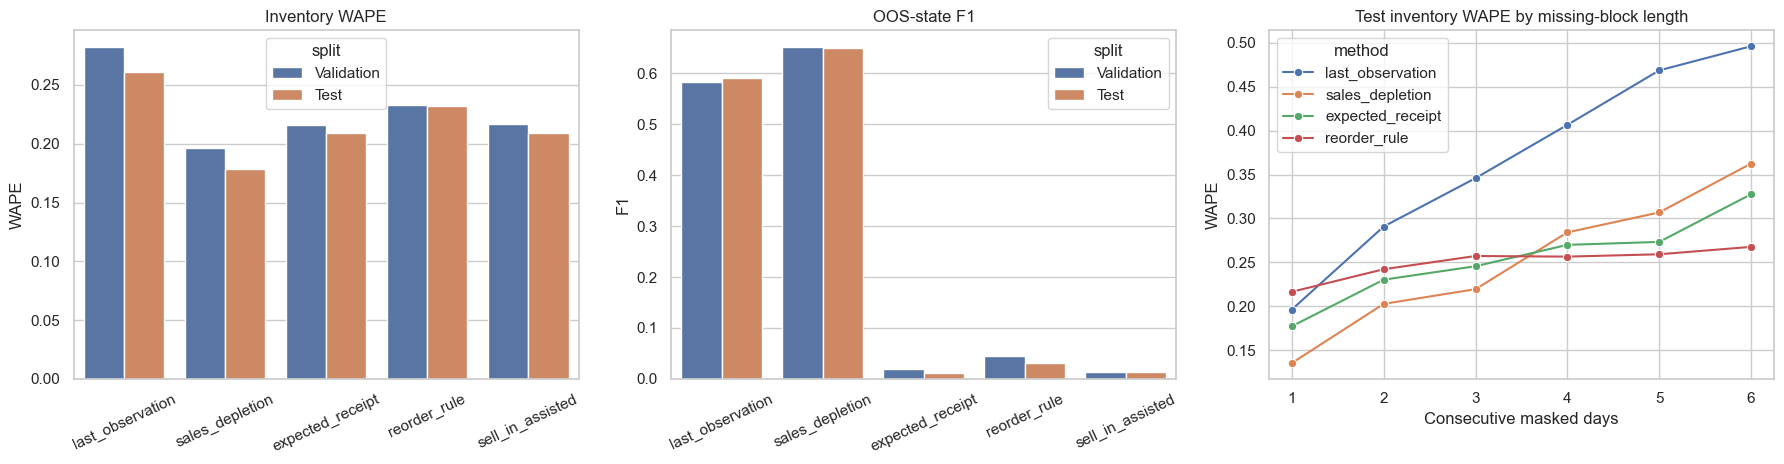

,channel,method,rows,MAE,WAPE,Bias,OOS_precision,OOS_recall,OOS_F1,status_accuracy
7,Modern Trade,sales_depletion,12230,9.031,0.167,-6.681,0.517,0.873,0.649,0.905
13,Traditional Trade,sales_depletion,10384,5.264,0.190,-3.326,0.534,0.852,0.657,0.860
1,Distributor,sales_depletion,4925,9.026,0.197,-6.785,0.493,0.896,0.636,0.882


,mask_block_length,method,rows,MAE,WAPE,Bias,OOS_precision,OOS_recall,OOS_F1,status_accuracy
1,1,sales_depletion,13519,5.897,0.136,-3.802,0.630,0.884,0.736,0.913
7,2,sales_depletion,8118,8.873,0.203,-6.749,0.509,0.871,0.642,0.877
13,3,sales_depletion,3633,9.029,0.220,-6.288,0.442,0.801,0.570,0.853
19,4,sales_depletion,1448,8.997,0.284,-7.059,0.315,0.873,0.463,0.789
25,5,sales_depletion,575,12.188,0.307,-10.035,0.229,0.846,0.361,0.788
31,6,sales_depletion,246,20.240,0.362,-18.813,0.245,0.929,0.388,0.776


In [27]:
display(inventory_scores)

deployable_methods = [
    "last_observation",
    "sales_depletion",
    "expected_receipt",
    "reorder_rule",
    "sell_in_assisted",
]
validation_deployable = inventory_scores.loc[
    (inventory_scores["split"] == "Validation")
    & inventory_scores["method"].isin(deployable_methods)
].sort_values(["WAPE", "MAE"])
selected_inventory_method = validation_deployable.iloc[0]["method"]

inventory_decision = pd.Series({
    "Validation-selected deployable method": selected_inventory_method,
    "Validation WAPE": validation_deployable.iloc[0]["WAPE"],
    "Validation OOS precision": validation_deployable.iloc[0]["OOS_precision"],
    "Validation OOS recall": validation_deployable.iloc[0]["OOS_recall"],
    "Validation OOS F1": validation_deployable.iloc[0]["OOS_F1"],
    "Test WAPE": inventory_scores.loc[
        (inventory_scores["split"] == "Test")
        & (inventory_scores["method"] == selected_inventory_method), "WAPE"
    ].iloc[0],
    "Test OOS precision": inventory_scores.loc[
        (inventory_scores["split"] == "Test")
        & (inventory_scores["method"] == selected_inventory_method), "OOS_precision"
    ].iloc[0],
    "Test OOS recall": inventory_scores.loc[
        (inventory_scores["split"] == "Test")
        & (inventory_scores["method"] == selected_inventory_method), "OOS_recall"
    ].iloc[0],
    "Test OOS F1": inventory_scores.loc[
        (inventory_scores["split"] == "Test")
        & (inventory_scores["method"] == selected_inventory_method), "OOS_F1"
    ].iloc[0],
})
display(inventory_decision.to_frame("value"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
plot_scores = inventory_scores.loc[inventory_scores["method"] != "oracle_sales_depletion"]
sns.barplot(data=plot_scores, x="method", y="WAPE", hue="split", ax=axes[0])
axes[0].set(title="Inventory WAPE", xlabel="", ylabel="WAPE")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(data=plot_scores, x="method", y="OOS_F1", hue="split", ax=axes[1])
axes[1].set(title="OOS-state F1", xlabel="", ylabel="F1")
axes[1].tick_params(axis="x", rotation=25)

sns.lineplot(
    data=inventory_test_gap_scores.loc[
        inventory_test_gap_scores["method"].isin([
            "last_observation", "sales_depletion", "expected_receipt", "reorder_rule"
        ])
    ],
    x="mask_block_length", y="WAPE", hue="method", marker="o", ax=axes[2]
)
axes[2].set(
    title="Test inventory WAPE by missing-block length",
    xlabel="Consecutive masked days", ylabel="WAPE"
)
plt.tight_layout()
plt.show()

display(
    inventory_test_channel_scores.loc[
        inventory_test_channel_scores["method"] == selected_inventory_method
    ].sort_values("WAPE")
)
display(
    inventory_test_gap_scores.loc[
        inventory_test_gap_scores["method"] == selected_inventory_method
    ].sort_values("mask_block_length")
)

### Inventory experiment findings

- `sales_depletion` is the validation-selected deployable baseline. It achieves 19.6% validation WAPE and 17.8% test WAPE.
- On the June test masks, `sales_depletion` reaches 51.9% OOS precision, 86.9% recall, and 65.0% F1. Its high recall is useful for an early-warning workflow, although false positives still require improvement.
- `last_observation` has 26.1% test WAPE and 59.0% OOS F1. It misses inventory consumption between reports and is inferior to depletion.
- Mean expected-receipt and Sell-in-assisted methods reduce average bias, but their near-zero OOS recall makes them unsuitable for the alerting objective. Adding small average receipts creates smooth positive inventories and hides stockout events.
- The deterministic reorder rule also misses most OOS events. Replenishment timing cannot be reliably reconstructed from low inventory alone.
- The non-deployable oracle-sales version reaches 14.3% test WAPE and 71.0% OOS F1. The improvement over estimated-sales depletion shows that sales imputation matters, while the remaining error quantifies unobserved replenishment uncertainty.
- For the selected method, WAPE rises from 13.6% for one-day gaps to 36.2% for six-day gaps. The product should label estimates and expose the last reported date; long gaps should receive lower operational trust without displaying a complicated confidence score.
- The same depletion mechanics work across all three channels: test WAPE is 16.7% for Modern Trade, 19.0% for Traditional Trade, and 19.7% for Distributor. Distributor may still require separate business rules and features later, but this experiment does not support a separate inventory-imputation algorithm.

**Provisional inventory method:** carry the most recent reported inventory forward through a stock-flow equation, subtract the store-SKU-weekday sales estimate each day, floor at zero, and label all generated values as estimated. Do not add Sell-in units directly. Preserve the 12-day Sell-in feature for the later OOS model, where a supervised model can decide whether it adds predictive value.


## 15.3 Decision and next experiment

The missing-day layer now has an evidence-based MVP baseline:

- Sales: store-SKU-weekday median with hierarchical fallback.
- Inventory: sequential sales depletion from the last reported inventory.
- Status: every reconstructed row retains `is_reported = False`, `sales_was_imputed = True`, and `inventory_was_imputed = True`.
- Product display: estimated values are shown by default with an estimated label and last-reported date; the observed-only view remains available.

The next experiment should measure downstream impact on the actual Module 2 target: any observed OOS during the next seven days. It should compare OOS models trained with observed-only features versus features augmented by the selected missing-day estimates, using a chronological split and a seven-day purge gap.


# 16. Downstream Seven-Day OOS Impact Experiment

The previous experiments established explainable estimates for missing sales and inventory. This section tests the downstream question that matters for Module 2: **do those estimates improve prediction of any OOS event during the next seven calendar days?**

The experiment compares two feature sets on exactly the same labeled rows and chronological splits:

- `Observed-only`: latest reported inventory and OOS state, observed sales velocity, reporting coverage and freshness, recent Sell-in, calendar, account, and product attributes.
- `Observed + estimated`: all observed-only features plus estimated current inventory, estimated 7/28-day sales velocity, estimated days of supply, and an imputation flag.

This isolates the incremental value of the missing-day estimates. It does not compare different samples or manufacture labels from imputed future values.


## 16.1 Strict target and chronological experiment design

The target is `1` when at least one OOS event is observed from `t+1` through `t+7`. A formal negative is accepted only when all seven future calendar days are reported and none is OOS. Incomplete future windows remain unknown and are excluded from formal model training and evaluation.

Prediction dates are divided chronologically. Seven unused calendar days separate training from validation and validation from test, preventing the outcome windows from crossing into the next evaluation period.

The current prototype assumes an end-of-day score using information available through date `t`. If the production ranking must run before the end-of-day report, all same-day features must be shifted by one day.


In [28]:
TRAIN_END = pd.Timestamp("2026-04-23")
VALIDATION_START = pd.Timestamp("2026-05-01")
VALIDATION_END = pd.Timestamp("2026-05-24")
TEST_START = pd.Timestamp("2026-06-01")
TEST_END = pd.Timestamp("2026-06-23")


def rolling_by_pair(frame, column, window, aggregation="sum"):
    rolling = frame.groupby(["store_id", "sku_id"], sort=False)[column].rolling(
        window=window, min_periods=1
    )
    result = getattr(rolling, aggregation)()
    return result.reset_index(level=[0, 1], drop=True).sort_index()


def build_daily_panel():
    pairs = sell_out[["store_id", "sku_id"]].drop_duplicates().merge(
        stores[["store_id", "channel", "segment_tier", "region"]],
        on="store_id", how="left", validate="many_to_one",
    ).merge(
        products[["sku_id", "category", "is_msl"]],
        on="sku_id", how="left", validate="many_to_one",
    )
    dates = pd.DataFrame({"date": pd.date_range(sell_out["date"].min(), sell_out["date"].max())})
    pairs["_key"] = 1
    dates["_key"] = 1
    panel = pairs.merge(dates, on="_key").drop(columns="_key")
    panel = panel.merge(
        sell_out,
        on=["date", "store_id", "sku_id"],
        how="left",
        validate="one_to_one",
    ).sort_values(["store_id", "sku_id", "date"]).reset_index(drop=True)
    panel["is_reported"] = panel["inventory_level"].notna()
    panel["is_out_of_stock"] = panel["is_out_of_stock"].astype("boolean")
    panel["weekday"] = panel["date"].dt.dayofweek

    # Strict target: all seven future calendar days must be observed.
    pair_group = panel.groupby(["store_id", "sku_id"], sort=False)
    complete = np.ones(len(panel), dtype=bool)
    any_oos = np.zeros(len(panel), dtype=bool)
    for horizon in range(1, 8):
        future_reported = pair_group["is_reported"].shift(-horizon).eq(True).to_numpy(
            dtype=bool, na_value=False
        )
        future_oos = pair_group["is_out_of_stock"].shift(-horizon).eq(True).to_numpy(
            dtype=bool, na_value=False
        )
        complete &= future_reported
        any_oos |= future_oos
    panel["future_7d_complete"] = complete
    panel["target_any_oos_next_7d"] = np.where(complete, any_oos.astype(int), np.nan)

    # Training-fitted sales imputer, reused for all splits.
    sales_train = panel.loc[
        (panel["date"] <= TRAIN_END)
        & panel["is_reported"]
        & panel["is_out_of_stock"].ne(True)
    ].copy()
    detailed = sales_train.groupby(
        ["store_id", "sku_id", "weekday"], observed=True
    )["units_sold_daily"].median().rename("detailed_sales")
    pair_median = sales_train.groupby(
        ["store_id", "sku_id"], observed=True
    )["units_sold_daily"].median().rename("pair_sales")
    fallback = sales_train.groupby(
        ["channel", "sku_id", "weekday"], observed=True
    )["units_sold_daily"].median().rename("fallback_sales")
    overall = float(sales_train["units_sold_daily"].median())

    panel = panel.join(detailed, on=["store_id", "sku_id", "weekday"])
    panel = panel.join(pair_median, on=["store_id", "sku_id"])
    panel = panel.join(fallback, on=["channel", "sku_id", "weekday"])
    panel["imputed_sales_daily"] = (
        panel["detailed_sales"]
        .fillna(panel["pair_sales"])
        .fillna(panel["fallback_sales"])
        .fillna(overall)
    )
    panel["estimated_sales_daily"] = panel["units_sold_daily"].fillna(
        panel["imputed_sales_daily"]
    )

    # Observed-only state and reporting freshness.
    panel["latest_reported_inventory"] = panel.groupby(
        ["store_id", "sku_id"], sort=False
    )["inventory_level"].ffill()
    panel["latest_reported_oos"] = panel.groupby(
        ["store_id", "sku_id"], sort=False
    )["is_out_of_stock"].ffill().eq(True).fillna(False).astype(int)
    date_number = (panel["date"] - panel["date"].min()).dt.days.astype(float)
    last_report_number = date_number.where(panel["is_reported"]).groupby(
        [panel["store_id"], panel["sku_id"]], sort=False
    ).ffill()
    panel["days_since_last_report"] = date_number - last_report_number

    panel["observed_sales_for_sum"] = panel["units_sold_daily"].fillna(0)
    panel["observed_count"] = panel["is_reported"].astype(int)
    for window in (7, 28):
        observed_sum = rolling_by_pair(panel, "observed_sales_for_sum", window)
        observed_count = rolling_by_pair(panel, "observed_count", window)
        panel[f"observed_sales_mean_{window}d"] = observed_sum / observed_count.replace(0, np.nan)
        panel[f"report_coverage_{window}d"] = observed_count / window
        panel[f"estimated_sales_mean_{window}d"] = rolling_by_pair(
            panel, "estimated_sales_daily", window, aggregation="mean"
        )
    panel["observed_oos_numeric"] = (
        panel["is_out_of_stock"].eq(True).fillna(False).astype(int)
    )
    panel["observed_oos_count_28d"] = rolling_by_pair(panel, "observed_oos_numeric", 28)

    # Sequential depletion between reports, efficiently reset by every observed row.
    panel["inventory_segment"] = panel.groupby(
        ["store_id", "sku_id"], sort=False
    )["is_reported"].cumsum()
    panel["missing_day_sales"] = np.where(
        panel["is_reported"], 0.0, panel["estimated_sales_daily"]
    )
    cumulative_missing_sales = panel.groupby(
        ["store_id", "sku_id", "inventory_segment"], sort=False
    )["missing_day_sales"].cumsum()
    panel["estimated_inventory"] = (
        panel["latest_reported_inventory"] - cumulative_missing_sales
    ).clip(lower=0)
    panel["inventory_was_imputed"] = (~panel["is_reported"]).astype(int)

    panel["observed_days_of_supply"] = (
        panel["latest_reported_inventory"]
        / panel["observed_sales_mean_28d"].clip(lower=0.25)
    ).clip(upper=365)
    panel["estimated_days_of_supply"] = (
        panel["estimated_inventory"]
        / panel["estimated_sales_mean_28d"].clip(lower=0.25)
    ).clip(upper=365)

    # Common Sell-in history features. Invoice quantities are signals, not assumed receipts.
    invoices = sell_in.groupby(["store_id", "sku_id", "date"], as_index=False)["units_sold"].sum()
    invoices = invoices.rename(columns={"units_sold": "sell_in_units"})
    panel = panel.merge(invoices, on=["store_id", "sku_id", "date"], how="left")
    panel["sell_in_units"] = panel["sell_in_units"].fillna(0)
    panel["sell_in_units_28d"] = rolling_by_pair(panel, "sell_in_units", 28)
    invoice_date_number = date_number.where(panel["sell_in_units"].gt(0)).groupby(
        [panel["store_id"], panel["sku_id"]], sort=False
    ).ffill()
    panel["days_since_sell_in"] = (date_number - invoice_date_number).clip(upper=365)

    panel["weekday_sin"] = np.sin(2 * np.pi * panel["weekday"] / 7)
    panel["weekday_cos"] = np.cos(2 * np.pi * panel["weekday"] / 7)
    return panel


COMMON_NUMERIC = [
    "latest_reported_inventory",
    "latest_reported_oos",
    "days_since_last_report",
    "observed_sales_mean_7d",
    "observed_sales_mean_28d",
    "report_coverage_7d",
    "report_coverage_28d",
    "observed_oos_count_28d",
    "observed_days_of_supply",
    "sell_in_units_28d",
    "days_since_sell_in",
    "weekday_sin",
    "weekday_cos",
    "is_msl",
]

AUGMENTED_NUMERIC = COMMON_NUMERIC + [
    "estimated_inventory",
    "estimated_sales_mean_7d",
    "estimated_sales_mean_28d",
    "estimated_days_of_supply",
    "inventory_was_imputed",
]

CATEGORICAL = ["channel", "segment_tier", "region", "category"]


def split_name(date):
    if date <= TRAIN_END:
        return "Train"
    if VALIDATION_START <= date <= VALIDATION_END:
        return "Validation"
    if TEST_START <= date <= TEST_END:
        return "Test"
    return "Purge/Unused"


def prepare_model_data(panel):
    model_data = panel.loc[
        panel["future_7d_complete"]
        & (panel["date"] <= TEST_END)
        & panel["latest_reported_inventory"].notna()
    ].copy()
    model_data["split"] = model_data["date"].map(split_name)
    model_data = model_data.loc[model_data["split"].isin(["Train", "Validation", "Test"])]
    model_data["target"] = model_data["target_any_oos_next_7d"].astype(int)
    return model_data


def design_matrix(data, numeric_columns, fitted=None):
    numeric = data[numeric_columns].astype(float).replace([np.inf, -np.inf], np.nan)
    categories = pd.get_dummies(data[CATEGORICAL], prefix=CATEGORICAL, dtype=float)
    frame = pd.concat([numeric, categories], axis=1)
    if fitted is None:
        medians = frame.median().fillna(0)
        frame = frame.fillna(medians)
        means = frame.mean()
        scales = frame.std(ddof=0).replace(0, 1)
        fitted = {
            "columns": frame.columns.tolist(),
            "medians": medians,
            "means": means,
            "scales": scales,
        }
    else:
        frame = frame.reindex(columns=fitted["columns"], fill_value=0)
        frame = frame.fillna(fitted["medians"])
    scaled = (frame - fitted["means"]) / fitted["scales"]
    return scaled.to_numpy(dtype=np.float64), fitted


def sigmoid(values):
    values = np.clip(values, -35, 35)
    return 1 / (1 + np.exp(-values))


def fit_logistic_regression(x, y, iterations=140, learning_rate=0.08, l2=0.02):
    x_with_intercept = np.column_stack([np.ones(len(x)), x])
    weights = np.zeros(x_with_intercept.shape[1])
    positive_rate = y.mean()
    sample_weight = np.where(y == 1, 0.5 / positive_rate, 0.5 / (1 - positive_rate))
    for iteration in range(iterations):
        prediction = sigmoid(x_with_intercept @ weights)
        gradient = x_with_intercept.T @ (sample_weight * (prediction - y)) / len(y)
        penalty = np.r_[0.0, weights[1:]] * l2
        step = learning_rate / np.sqrt(1 + iteration / 35)
        weights -= step * (gradient + penalty)
    return weights


def predict_probability(x, weights):
    return sigmoid(np.column_stack([np.ones(len(x)), x]) @ weights)


def roc_auc(y, probability):
    ranks = pd.Series(probability).rank(method="average").to_numpy()
    positive = y == 1
    n_positive = positive.sum()
    n_negative = len(y) - n_positive
    return (
        ranks[positive].sum() - n_positive * (n_positive + 1) / 2
    ) / (n_positive * n_negative)


def classification_metrics(y, probability, threshold):
    predicted = probability >= threshold
    actual = y == 1
    tp = int((predicted & actual).sum())
    fp = int((predicted & ~actual).sum())
    fn = int((~predicted & actual).sum())
    tn = int((~predicted & ~actual).sum())
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "threshold": threshold,
        "AUC_ROC": roc_auc(y, probability),
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "predicted_positive_rate": predicted.mean(),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    }


def choose_threshold(y, probability, minimum_recall=0.70):
    candidates = np.unique(np.quantile(probability, np.linspace(0.02, 0.98, 193)))
    scored = pd.DataFrame([classification_metrics(y, probability, value) for value in candidates])
    eligible = scored.loc[scored["recall"] >= minimum_recall]
    if eligible.empty:
        selected = scored.sort_values(["recall", "precision"], ascending=False).iloc[0]
    else:
        selected = eligible.sort_values(["precision", "F1", "threshold"], ascending=False).iloc[0]
    return float(selected["threshold"]), scored


def run_feature_experiment(model_data, name, numeric_columns):
    train = model_data.loc[model_data["split"] == "Train"]
    validation = model_data.loc[model_data["split"] == "Validation"]
    test = model_data.loc[model_data["split"] == "Test"]
    x_train, fitted = design_matrix(train, numeric_columns)
    x_validation, _ = design_matrix(validation, numeric_columns, fitted)
    x_test, _ = design_matrix(test, numeric_columns, fitted)
    y_train = train["target"].to_numpy()
    y_validation = validation["target"].to_numpy()
    y_test = test["target"].to_numpy()
    weights = fit_logistic_regression(x_train, y_train)
    validation_probability = predict_probability(x_validation, weights)
    test_probability = predict_probability(x_test, weights)
    threshold, threshold_table = choose_threshold(y_validation, validation_probability)
    results = pd.DataFrame([
        {"feature_set": name, "split": "Validation", **classification_metrics(
            y_validation, validation_probability, threshold
        )},
        {"feature_set": name, "split": "Test", **classification_metrics(
            y_test, test_probability, threshold
        )},
    ])
    test_predictions = test[[
        "date", "store_id", "sku_id", "channel", "is_reported", "target"
    ]].copy()
    test_predictions["probability"] = test_probability
    test_predictions["predicted"] = test_probability >= threshold
    coefficients = pd.DataFrame({
        "feature": fitted["columns"],
        "coefficient": weights[1:],
    })
    coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()
    return results, test_predictions, coefficients, threshold_table


oos_daily_panel = build_daily_panel()
oos_model_data = prepare_model_data(oos_daily_panel)

observed_results, observed_test_predictions, observed_coefficients, observed_thresholds = (
    run_feature_experiment(oos_model_data, "Observed-only", COMMON_NUMERIC)
)
augmented_results, augmented_test_predictions, augmented_coefficients, augmented_thresholds = (
    run_feature_experiment(oos_model_data, "Observed + estimated", AUGMENTED_NUMERIC)
)
oos_model_results = pd.concat([observed_results, augmented_results], ignore_index=True)


def segment_metrics(predictions, feature_set):
    rows = []
    for reported, group in predictions.groupby("is_reported", observed=True):
        metrics = classification_metrics(
            group["target"].to_numpy(),
            group["probability"].to_numpy(),
            0.5,
        )
        # The stored prediction already uses the validation-selected threshold.
        actual = group["target"].eq(1)
        predicted = group["predicted"]
        tp = int((actual & predicted).sum())
        fp = int((~actual & predicted).sum())
        fn = int((actual & ~predicted).sum())
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall = tp / (tp + fn) if tp + fn else np.nan
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        rows.append({
            "feature_set": feature_set,
            "current_day_reported": bool(reported),
            "rows": len(group),
            "positive_rate": actual.mean(),
            "AUC_ROC": metrics["AUC_ROC"],
            "precision": precision,
            "recall": recall,
            "F1": f1,
        })
    return pd.DataFrame(rows)


oos_test_reporting_segment = pd.concat([
    segment_metrics(observed_test_predictions, "Observed-only"),
    segment_metrics(augmented_test_predictions, "Observed + estimated"),
], ignore_index=True)


def daily_priority_metrics(predictions, feature_set, fractions=(0.10, 0.20)):
    rows = []
    for fraction in fractions:
        selected_parts = []
        for _, day in predictions.groupby("date", sort=False):
            number_selected = max(1, int(np.ceil(len(day) * fraction)))
            selected_parts.append(day.nlargest(number_selected, "probability"))
        selected = pd.concat(selected_parts, ignore_index=True)
        positives = predictions["target"].sum()
        selected_positives = selected["target"].sum()
        precision = selected["target"].mean()
        base_rate = predictions["target"].mean()
        rows.append({
            "feature_set": feature_set,
            "daily_priority_fraction": fraction,
            "selected_rows": len(selected),
            "precision_at_fraction": precision,
            "recall_at_fraction": selected_positives / positives,
            "lift_vs_random": precision / base_rate,
        })
    return pd.DataFrame(rows)


oos_test_priority_metrics = pd.concat([
    daily_priority_metrics(observed_test_predictions, "Observed-only"),
    daily_priority_metrics(augmented_test_predictions, "Observed + estimated"),
], ignore_index=True)

oos_split_summary = oos_model_data.groupby("split", observed=True).agg(
    rows=("target", "size"),
    positive_rate=("target", "mean"),
    current_day_report_rate=("is_reported", "mean"),
    start_date=("date", "min"),
    end_date=("date", "max"),
).reset_index()

In [29]:
display(oos_split_summary)

label_summary = pd.Series({
    "Target": "Any observed OOS from t+1 through t+7",
    "Formal negative requirement": "All seven future calendar days observed and no OOS",
    "Formal positive requirement": "All seven future calendar days observed and at least one OOS",
    "Imputed future values used as labels": False,
    "Train end": TRAIN_END.date(),
    "Validation window": f"{VALIDATION_START.date()} to {VALIDATION_END.date()}",
    "Test window": f"{TEST_START.date()} to {TEST_END.date()}",
    "Purge gap before validation": "7 calendar days",
    "Purge gap before test": "7 calendar days",
})
display(label_summary.to_frame("value"))

,split,rows,positive_rate,current_day_report_rate,start_date,end_date
0,Test,7872,0.176,0.705,2026-06-01,2026-06-23
1,Train,166242,0.170,0.702,2025-01-01,2026-04-23
2,Validation,7203,0.166,0.637,2026-05-01,2026-05-24


,value
Target,Any observed OOS from t+1 through t+7
Formal negative requirement,All seven future calendar days observed and no...
Formal positive requirement,All seven future calendar days observed and at...
Imputed future values used as labels,False
Train end,2026-04-23
Validation window,2026-05-01 to 2026-05-24
Test window,2026-06-01 to 2026-06-23
Purge gap before validation,7 calendar days
Purge gap before test,7 calendar days


### Label and sample findings

- The strict complete-window rule produces 166,242 training rows, 7,203 validation rows, and 7,872 final test rows.
- Positive prevalence is stable at approximately 16.6% to 17.6% across the three periods.
- The model never uses estimated future inventory or estimated future OOS as a supervised label.
- The formal sample is reliable for model comparison, but it represents account-SKU dates with complete future reporting. Its performance may not fully generalize to all incompletely reported windows.


## 16.2 Controlled model comparison

A regularized, class-weighted Logistic Regression is used as the explainable baseline. Its implementation uses only NumPy so the experiment remains reproducible in the current locked environment.

For each feature set, the decision threshold is selected on validation data by finding the highest precision that still achieves at least 70% validation recall. That threshold is then frozen and applied to the June test period. AUC is threshold-independent.

The daily priority-list evaluation separately asks whether a sales representative would see more true future-OOS store-SKUs by visiting the top 10% or top 20% of model-ranked rows each day.


,feature_set,split,threshold,AUC_ROC,precision,recall,F1,predicted_positive_rate,TP,FP,FN,TN
0,Observed-only,Validation,0.603,0.890,0.478,0.707,0.570,0.245,843,922,350,5088
1,Observed-only,Test,0.603,0.878,0.475,0.693,0.564,0.256,960,1059,426,5427
2,Observed + estimated,Validation,0.655,0.892,0.484,0.701,0.572,0.240,836,893,357,5117
3,Observed + estimated,Test,0.655,0.881,0.483,0.683,0.565,0.249,946,1014,440,5472


,feature_set,current_day_reported,rows,positive_rate,AUC_ROC,precision,recall,F1
0,Observed-only,False,2323,0.166,0.870,0.446,0.697,0.544
1,Observed-only,True,5549,0.180,0.882,0.488,0.691,0.572
2,Observed + estimated,False,2323,0.166,0.873,0.448,0.697,0.545
3,Observed + estimated,True,5549,0.180,0.885,0.498,0.677,0.574


,feature_set,daily_priority_fraction,selected_rows,precision_at_fraction,recall_at_fraction,lift_vs_random
0,Observed-only,0.100,798,0.644,0.371,3.658
1,Observed-only,0.200,1585,0.527,0.602,2.992
2,Observed + estimated,0.100,798,0.638,0.367,3.623
3,Observed + estimated,0.200,1585,0.526,0.602,2.989


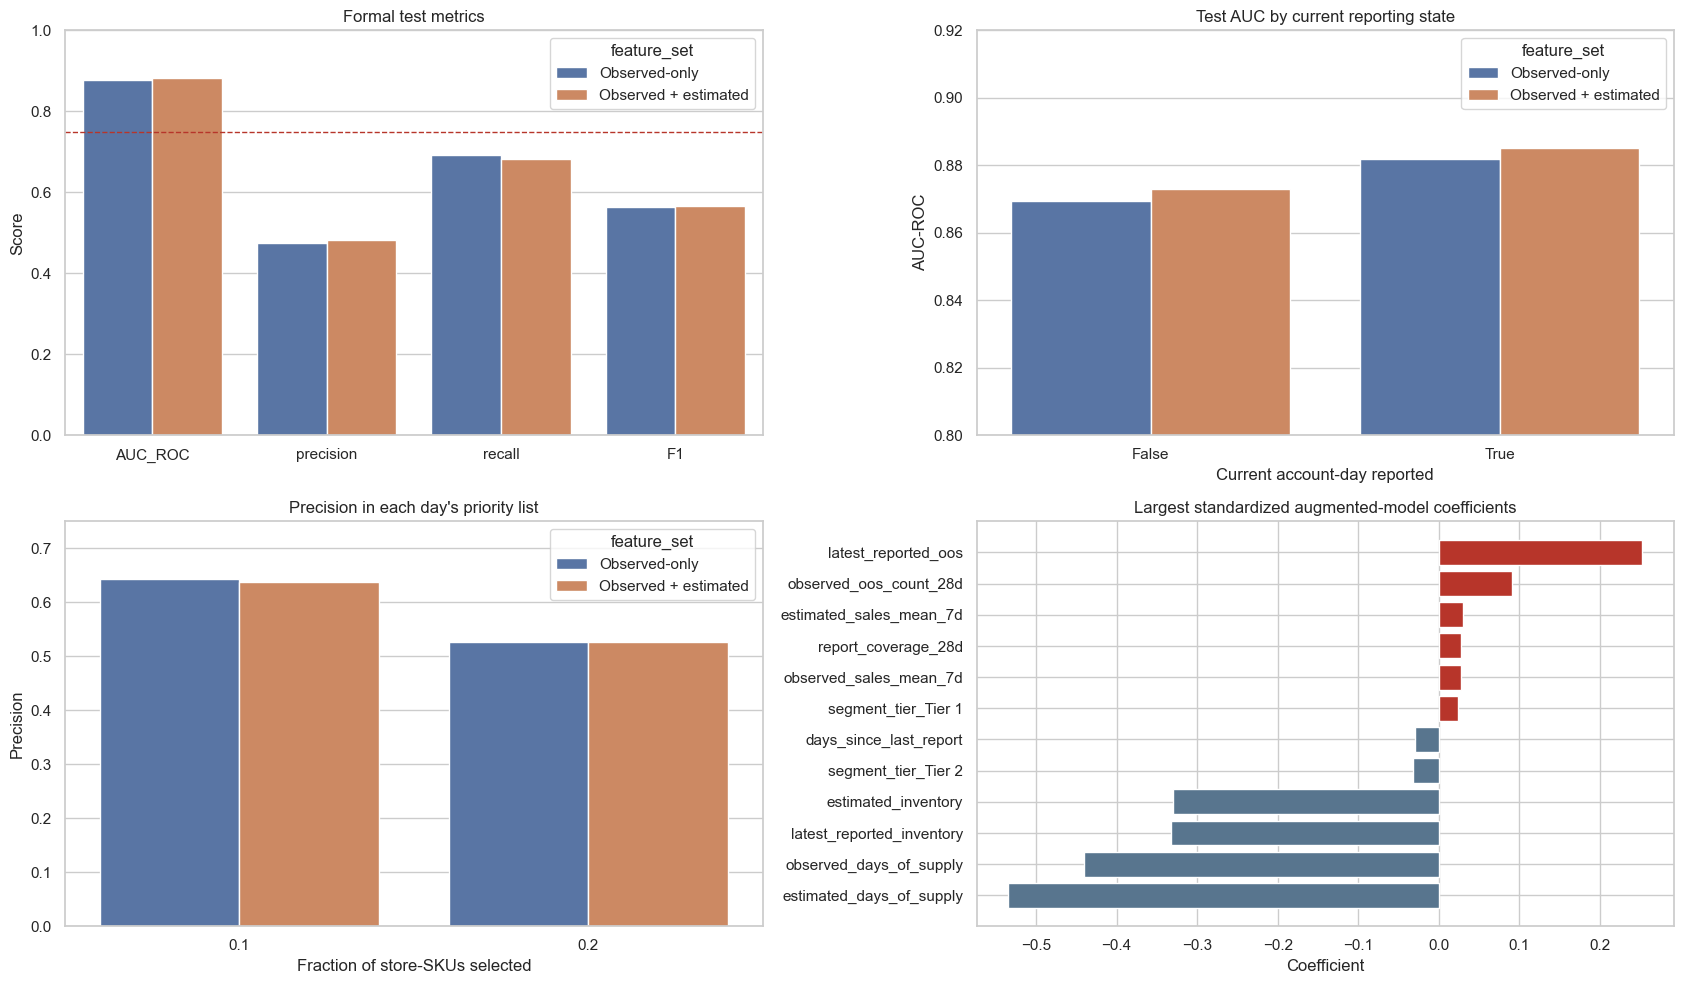

In [30]:
display(oos_model_results)
display(oos_test_reporting_segment)
display(oos_test_priority_metrics)

metric_long = oos_model_results.melt(
    id_vars=["feature_set", "split"],
    value_vars=["AUC_ROC", "precision", "recall", "F1"],
    var_name="metric", value_name="value",
)
top_coefficients = (
    augmented_coefficients
    .sort_values("absolute_coefficient", ascending=False)
    .head(12)
    .sort_values("coefficient")
)

fig, axes = plt.subplots(2, 2, figsize=(17, 10))
sns.barplot(
    data=metric_long.loc[metric_long["split"] == "Test"],
    x="metric", y="value", hue="feature_set", ax=axes[0, 0]
)
axes[0, 0].axhline(0.75, color=COLORS["red"], linestyle="--", linewidth=1, label="Precision target")
axes[0, 0].set(title="Formal test metrics", xlabel="", ylabel="Score", ylim=(0, 1))

sns.barplot(
    data=oos_test_reporting_segment,
    x="current_day_reported", y="AUC_ROC", hue="feature_set", ax=axes[0, 1]
)
axes[0, 1].set(
    title="Test AUC by current reporting state",
    xlabel="Current account-day reported", ylabel="AUC-ROC", ylim=(0.80, 0.92)
)

sns.barplot(
    data=oos_test_priority_metrics,
    x="daily_priority_fraction", y="precision_at_fraction", hue="feature_set", ax=axes[1, 0]
)
axes[1, 0].set(
    title="Precision in each day's priority list",
    xlabel="Fraction of store-SKUs selected", ylabel="Precision", ylim=(0, 0.75)
)

axes[1, 1].barh(
    top_coefficients["feature"], top_coefficients["coefficient"],
    color=np.where(top_coefficients["coefficient"] >= 0, COLORS["red"], COLORS["blue"])
)
axes[1, 1].set(title="Largest standardized augmented-model coefficients", xlabel="Coefficient")
plt.tight_layout()
plt.show()

### Downstream findings

- Adding estimated features increases formal test AUC from 0.8783 to 0.8814 and test F1 from 0.5639 to 0.5655. The improvement is real but operationally small.
- On currently unreported account-days, AUC rises from 0.8696 to 0.8729 and F1 from 0.5440 to 0.5451. This is the segment where imputation should help most, yet the gain remains modest.
- The augmented model reaches 48.3% test precision and 68.3% test recall at the validation-selected threshold. It exceeds the 0.80 AUC requirement, but does **not** meet the client targets of 0.75 precision and 0.70 recall.
- The small validation-to-test recall decline shows why the threshold must be frozen before testing rather than retuned on June.
- For each day's top 10% priority list, the observed-only model has 64.4% precision and 3.66x lift over random selection. The augmented model has 63.8% precision and 3.62x lift. Estimated features therefore do not improve the highest-priority ranking in this linear baseline.
- Inventory and days of supply dominate the standardized coefficients. Recent OOS history is also important. Static channel, tier, region, and category indicators contribute much less after inventory state is known.

**Decision:** retain the missing-day estimates for the operational dashboard and as candidate model features, but do not assume that imputation automatically improves OOS prediction. The observed-only plus reporting-freshness model is the stronger simple ranking baseline. The final model should test nonlinear algorithms and interactions before choosing its production feature set.


## 16.3 Implications for Module 2

1. Keep strict observed labels for formal validation and test.
2. Preserve estimated inventory and sales as visibly estimated operational states.
3. Always include reporting coverage, days since last report, and imputation flags so the model can distinguish facts from estimates.
4. Evaluate nonlinear models after the ML dependency is added to the locked environment. Candidate models include HistGradientBoosting and Random Forest; selection must use the same chronological splits and frozen June test set.
5. Report both classification metrics and daily priority-list metrics. The product acts on a ranked worklist, so AUC alone is insufficient.
6. Do not claim that the client precision and recall targets have been met. This experiment is the explainable baseline and a feature-value test, not the final Module 2 model.
